In [33]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from redim.pca import PCAresult
from redim.plots import annotate_plot
from wlp_chemspace.rdkit_utils import scaffold_from_smiles, basic_descriptors_from_smiles
from copy import deepcopy
import numpy as np
from rdkit import Chem

In [34]:
def get_adc_maxphase(status: str) -> str:
    if status is None:
        return None
    if "approved" in status.lower():
        return "Approved"
    elif "phase 3" in status.lower():
        return "Phase 3"
    elif "phase 2" in status.lower():
        return "Phase 2"
    elif "phase 1" in status.lower():
        return "Phase 1"
    elif "investigative" in status.lower():
        return "Investigative"
    elif "terminated" in status.lower():
        return "Terminated"
    else:
        return "Unknown"

def get_adc_approved(status: str) -> bool:
    if status is None:
        return False
    if "approved" in status.lower():
        return True
    else:
        return False

def get_adc_terminated(status: str) -> bool:
    if status is None:
        return False
    if "terminated" in status.lower() or "withdrawn" in status.lower():
        return True
    else:
        return False

def get_adc_clinical(status: str) -> bool:
    if status is None:
        return False
    if "phase" in status.lower() or "approved" in status.lower():
        return True
    else:
        return False

def get_antibody_classification():
    return


def has_maleimide(smiles: str) -> bool|None:
    """
    Returns True if the molecule contains a maleimide moiety.
    """
    # Maleimide core: five-membered imide ring with a C=C bond
    MALEIMIDE_SMARTS = "[#6]1=CC(=O)N([#6,#1]*)C(=O)1"

    maleimide_pattern = Chem.MolFromSmarts(MALEIMIDE_SMARTS)
    try:
       mol = Chem.MolFromSmiles(smiles)
    except:
        print(f"Invalid SMILES: {smiles}")
        return None
    return mol.HasSubstructMatch(maleimide_pattern)

In [35]:
def plot_histogram(df: pd.DataFrame, key: str, factor: float = 1.0, log: bool = False, xlim_bottom: float = None, xlim_top: float = None, ax=None) -> None:
    fontsize=24
    if ax is None:
       fig, ax = plt.subplots(figsize=(8,6))
    x=df[key]/factor

    bin_width = (xlim_top - xlim_bottom) / 50
    bins = np.arange(xlim_bottom, xlim_top + bin_width, bin_width)
    ax.hist(x, bins=bins,log=log,alpha=0.5, color="blue", edgecolor="black", linewidth=1.2)
    ax.set_xlim(left=xlim_bottom/factor,right=xlim_top/factor)
    
    # KDE
    kde_ax = sns.kdeplot(x, linewidth=3, color="red", ax=ax)
    # Rescale KDE from density to counts
    line = ax.lines[-1]
    N = len(x)
    bin_width = (xlim_top - xlim_bottom) / 50
    line.set_ydata(line.get_ydata() * N * bin_width)
    
    ax.set_ylabel("")
    ax.set_yticklabels([])
    
    if factor != 1.0:
       plt.xlabel(f"{key}/{factor}",fontsize=fontsize,fontweight="bold")
    else:   
        plt.xlabel(f"{key}",fontsize=fontsize,fontweight="bold")

    plt.xticks(fontsize=fontsize,fontweight="bold")
    plt.yticks(fontsize=fontsize,fontweight="bold")
    
    return

In [36]:
KEYS=["adc_id","adc_wlpsmiles","adc_meanDAR","adc_status","adc_conjugateType","linker_smiles","linker_type","payload_smiles","payload_class","plt_acronyms",]
DESCRIPTOR_KEYS=["NumAromaticRings", "NumHAcceptors", "NumHDonors", "NumRotatableBonds", "MW", "TPSA", "CrippenLogP"] # I also used "adc_meanDAR" in the past, but it is not a descriptor of the molecule itself, so I removed it from this list.
DESCRIPTOR_XLABELS=["No. Aromatic Rings","No. Hbond Acceptors","No. Hbond Donors","No. Rotatable Bonds","Molecular Weight","TPSA","Calculated logP"]
df=pd.read_csv("../.data/ADCdb_processed.csv").dropna(subset=KEYS).drop_duplicates(subset=KEYS).reset_index(drop=True)
df["adc_maxphase"]=df.adc_status.apply(get_adc_maxphase)
df["adc_approved"]=df.adc_status.apply(get_adc_approved)
df["adc_terminated"]=df.adc_status.apply(get_adc_terminated)
df["adc_clinical"]=df.adc_status.apply(get_adc_clinical)
print(df.columns)


Index(['adc_id', 'adc_name', 'adc_status', 'adc_conjugateType',
       'adc_conjugateShort', 'adc_meanDAR', 'adc_bottomDAR', 'adc_topDAR',
       'adc_wlpsmiles', 'adc_absorption', 'adc_distribution', 'adc_metabolism',
       'adc_elimination', 'adc_toxicity', 'adc_antibody_id', 'adc_linker_id',
       'adc_payload_id', 'adc_abt_id', 'adc_plt_id', 'antibody_id',
       'antibody_name', 'antibody_HC', 'antibody_vHC', 'antibody_cHC1',
       'antibody_cHC2', 'antibody_cHC3', 'antibody_LC', 'antibody_vLC',
       'antibody_cLC', 'linker_id', 'linker_name', 'linker_type',
       'linker_smiles', 'payload_id', 'payload_name', 'payload_smiles',
       'payload_class', 'abt_id', 'abt_name', 'plt_id', 'plt_name',
       'plt_acronyms', 'match_antibody', 'match_linker', 'match_payload',
       'match_abt', 'match_plt', 'adc_maxphase', 'adc_approved',
       'adc_terminated', 'adc_clinical'],
      dtype='str')


In [37]:
descriptors=pd.DataFrame([basic_descriptors_from_smiles(smiles) for smiles in df.adc_wlpsmiles])
adc_wlp_df=pd.concat([df, descriptors], axis=1)
adc_wlp_df=adc_wlp_df[(adc_wlp_df.MW>450) & (adc_wlp_df.MW<6000)].reset_index(drop=True)
adc_wlp_df=adc_wlp_df[(adc_wlp_df.NumAromaticRings<=14)].reset_index(drop=True)

# WLP Analysis

Maximum and minimum MW: 5679.997999999994, 466.3680000000001
Maximum and minimum NumAromaticRings: 12, 0
Maximum and minimum NumRotatableBonds: 260, 5
Maximum and minimum NumHAcceptors: 97, 6
Maximum and minimum NumHDonors: 40, 1
Maximum and minimum CrippenLogP: 13.518699999999958, -10.52315999999994
Maximum and minimum TPSA: 1428.660000000001, 115.05000000000001


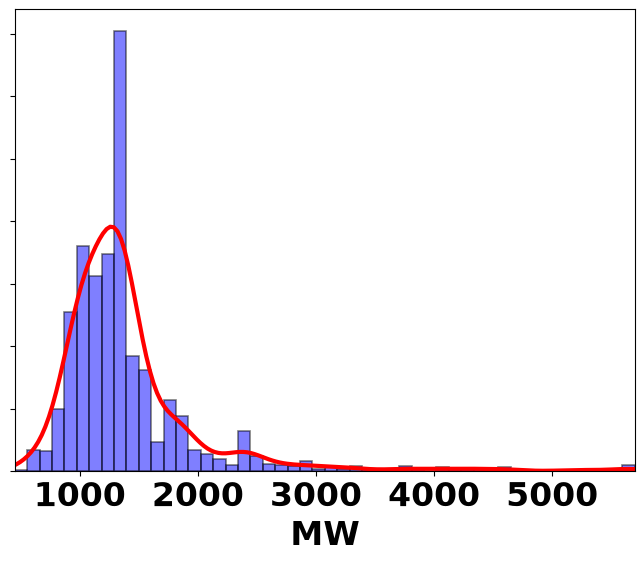

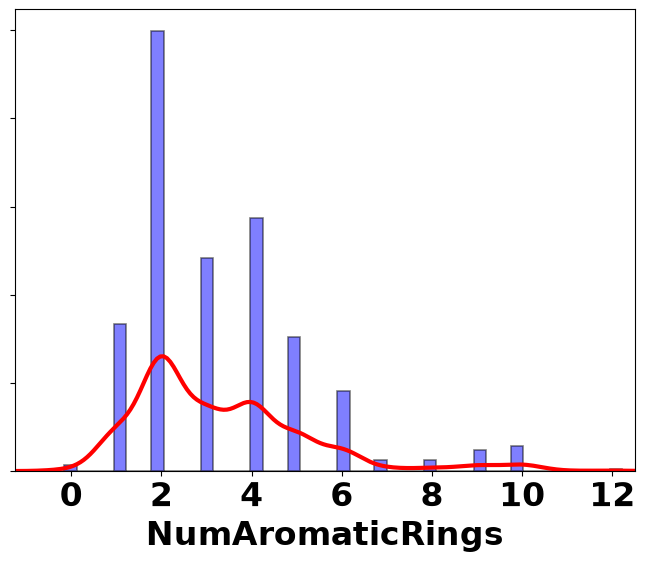

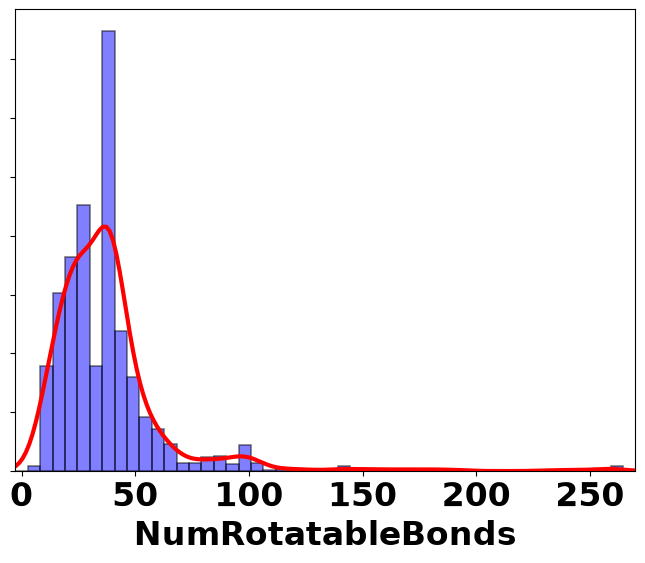

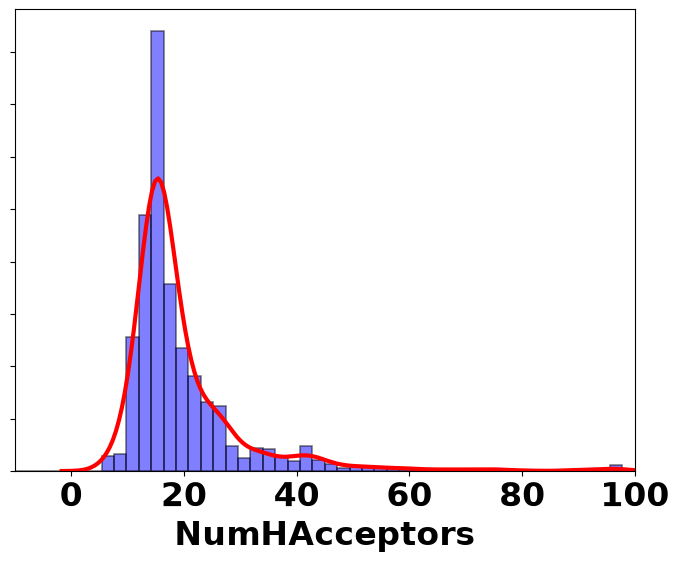

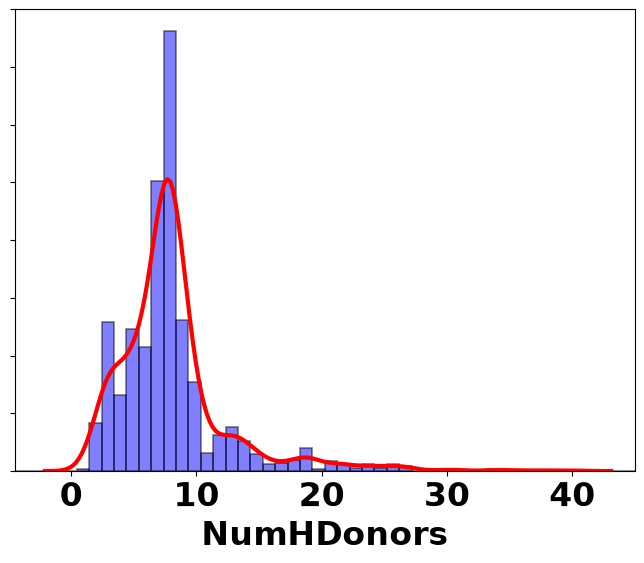

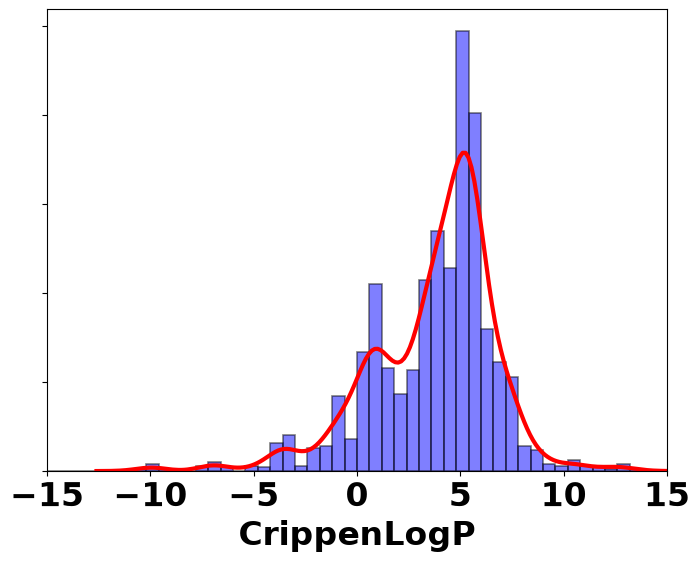

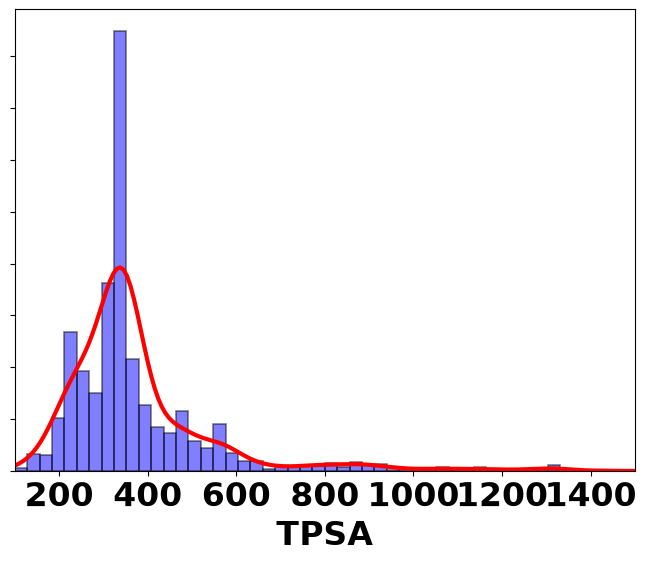

In [38]:
print(f"Maximum and minimum MW: {adc_wlp_df.MW.max()}, {adc_wlp_df.MW.min()}")
print(f"Maximum and minimum NumAromaticRings: {adc_wlp_df.NumAromaticRings.max()}, {adc_wlp_df.NumAromaticRings.min()}")
print(f"Maximum and minimum NumRotatableBonds: {adc_wlp_df.NumRotatableBonds.max()}, {adc_wlp_df.NumRotatableBonds.min()}")
print(f"Maximum and minimum NumHAcceptors: {adc_wlp_df.NumHAcceptors.max()}, {adc_wlp_df.NumHAcceptors.min()}")
print(f"Maximum and minimum NumHDonors: {adc_wlp_df.NumHDonors.max()}, {adc_wlp_df.NumHDonors.min()}")
print(f"Maximum and minimum CrippenLogP: {adc_wlp_df.CrippenLogP.max()}, {adc_wlp_df.CrippenLogP.min()}")
print(f"Maximum and minimum TPSA: {adc_wlp_df.TPSA.max()}, {adc_wlp_df.TPSA.min()}")
plot_histogram(df=adc_wlp_df, key="MW", factor=1, log=False, xlim_bottom=450, xlim_top=5700)
plot_histogram(df=adc_wlp_df, key="NumAromaticRings", factor=1.0, log=False, xlim_bottom=-1.25, xlim_top=12.5)
plot_histogram(df=adc_wlp_df, key="NumRotatableBonds", factor=1.0, log=False, xlim_bottom=-2.70, xlim_top=270)
plot_histogram(df=adc_wlp_df, key="NumHAcceptors", factor=1.0, log=False, xlim_bottom=-10, xlim_top=100)
plot_histogram(df=adc_wlp_df, key="NumHDonors", factor=1.0, log=False, xlim_bottom=-4.5, xlim_top=45)
plot_histogram(df=adc_wlp_df, key="CrippenLogP", factor=1.0, log=False, xlim_bottom=-15, xlim_top=15)
plot_histogram(df=adc_wlp_df, key="TPSA", factor=1, log=False, xlim_bottom=100, xlim_top=1500)

Number of clinical ADCs: 239
Number of non-clinical ADCs: 1286


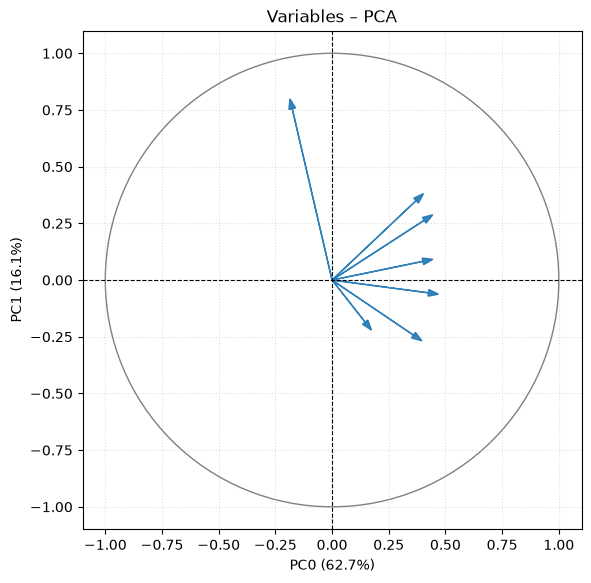

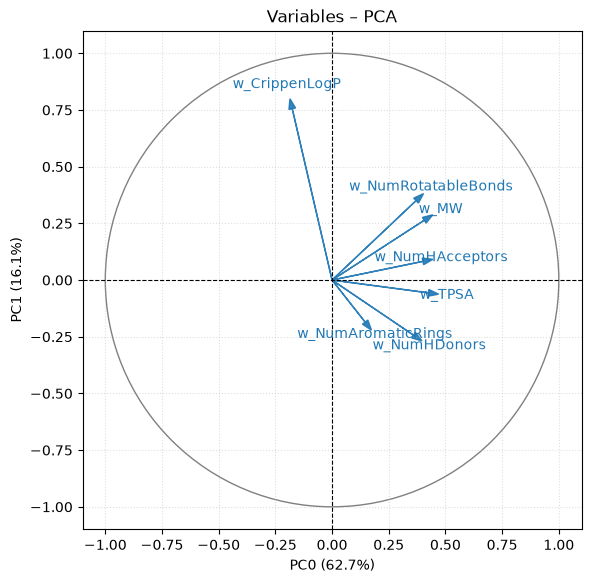

     w_NumAromaticRings  w_NumHAcceptors  w_NumHDonors  w_NumRotatableBonds  \
PC0            0.173820         0.444813      0.396298             0.403230   
PC1           -0.220857         0.091491     -0.268114             0.381178   
PC2            0.936652         0.010329     -0.139705            -0.163390   
PC3            0.006501        -0.415740      0.796893            -0.052114   
PC4            0.203282        -0.458088     -0.081705             0.786288   
PC5            0.046085         0.640232      0.236194             0.192322   
PC6           -0.014195         0.032917     -0.232470             0.086375   

         w_MW    w_TPSA  w_CrippenLogP  
PC0  0.444221  0.469526      -0.185727  
PC1  0.287984 -0.062268       0.799286  
PC2  0.040674 -0.029286       0.271753  
PC3 -0.152853  0.067171       0.401855  
PC4 -0.169847 -0.184579      -0.246964  
PC5 -0.539759 -0.443068       0.086919  
PC6 -0.611986  0.734793       0.150881  
62.68420065361975


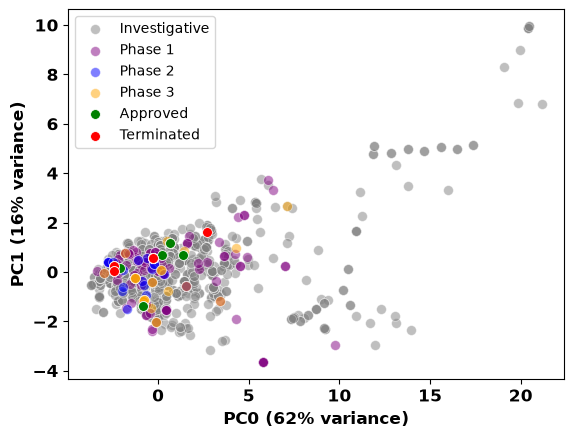

In [68]:

wlp_clinical_df=adc_wlp_df[adc_wlp_df.adc_clinical==True].reset_index(drop=True)
print(f"Number of clinical ADCs: {len(wlp_clinical_df)}")
wlp_nonclinical_df=adc_wlp_df[adc_wlp_df.adc_clinical==False].reset_index(drop=True)
print(f"Number of non-clinical ADCs: {len(wlp_nonclinical_df)}")
wlp_pca_training=PCAresult(wlp_clinical_df,feature_keys=DESCRIPTOR_KEYS)
wlp_pca_training.plot_pca_loadings(arrow_labels=False)
wlp_pca_training.plot_pca_loadings(arrow_labels=True)
print(wlp_pca_training.loadings_df)
print(wlp_pca_training.explained_variance_df.VarPerc.iloc[0])

df_pca_training=pd.concat([wlp_clinical_df,wlp_pca_training.components_df],axis=1)
df_pca_test=pd.concat([wlp_nonclinical_df,wlp_pca_training.project_dataframe(wlp_nonclinical_df)],axis=1)
df_pca=pd.concat([df_pca_training,df_pca_test],axis=0).reset_index(drop=True)
#sns.scatterplot(data=df_pca, x="PC0", y="PC1", hue="antibody_name", palette="viridis", s=25,alpha=0.5,legend=False)
sns.scatterplot(data=df_pca[df_pca.adc_maxphase=="Investigative"], x="PC0", y="PC1", color="gray", s=50,alpha=0.5, label="Investigative")
sns.scatterplot(data=df_pca[(df_pca.adc_maxphase=="Phase 1") & (df_pca.adc_terminated==False)], x="PC0", y="PC1", color="purple", s=50,alpha=0.5, label="Phase 1")
sns.scatterplot(data=df_pca[(df_pca.adc_maxphase=="Phase 2") & (df_pca.adc_terminated==False)], x="PC0", y="PC1", color="blue", s=50,alpha=0.5, label="Phase 2")
sns.scatterplot(data=df_pca[(df_pca.adc_maxphase=="Phase 3") & (df_pca.adc_terminated==False)], x="PC0", y="PC1", color="orange", s=50,alpha=0.5, label="Phase 3")
sns.scatterplot(data=df_pca[df_pca.adc_maxphase=="Approved"], x="PC0", y="PC1", color="green", s=50,alpha=1., label="Approved")
sns.scatterplot(data=df_pca[df_pca.adc_terminated==True], x="PC0", y="PC1", color="red", s=50,alpha=1., label="Terminated")
plt.xticks(fontsize=12,fontweight="bold")
plt.yticks(fontsize=12,fontweight="bold")
plt.xlabel(f"PC0 ({int(wlp_pca_training.explained_variance_df.VarPerc.iloc[0])}% variance)",fontsize=12,fontweight="bold")
plt.ylabel(f"PC1 ({int(wlp_pca_training.explained_variance_df.VarPerc.iloc[1])}% variance)",fontsize=12,fontweight="bold")
plt.legend()
plt.show()
plt.close()

In [40]:
df.antibody_name.value_counts()

antibody_name
Trastuzumab                              273
Anti-TNF mAb alpha-TNF                    31
Vandortuzumab                             23
mAb42                                     21
Mouse CD19 antibody                       20
                                        ... 
Daratumumab                                1
Imgatuzumab                                1
Naratuximab                                1
Chimeric ICAM1 antibody (clone #R6.5)      1
CD20-A antibody                            1
Name: count, Length: 613, dtype: int64

# Linker analysis

In [41]:
descriptors=pd.DataFrame([basic_descriptors_from_smiles(smiles) for smiles in df.linker_smiles])
print(descriptors.head())
linker_df=pd.concat([df, descriptors], axis=1)

   NumAromaticRings  NumHAcceptors  NumHDonors  NumRotatableBonds       MW  \
0                 1             13           7                 22  698.832   
1                 0              5           3                 11  381.429   
2                 1              7           6                 17  572.663   
3                 1              7           6                 17  572.663   
4                 0              6           0                  4  334.328   

     TPSA  CrippenLogP  
0  205.83       1.9882  
1  132.88       0.2019  
2  200.03       0.6769  
3  200.03       0.6769  
4  101.06       0.3250  


Maximum and minimum MW: 4323.805999999993, 106.146
Maximum and minimum NumAromaticRings: 8, 0
Maximum and minimum NumRotatableBonds: 229, 0
Maximum and minimum NumHAcceptors: 81, 0
Maximum and minimum NumHDonors: 37, 0
Maximum and minimum CrippenLogP: 9.118600000000011, -14.62729999999987
Maximum and minimum TPSA: 1229.6200000000013, 0.0


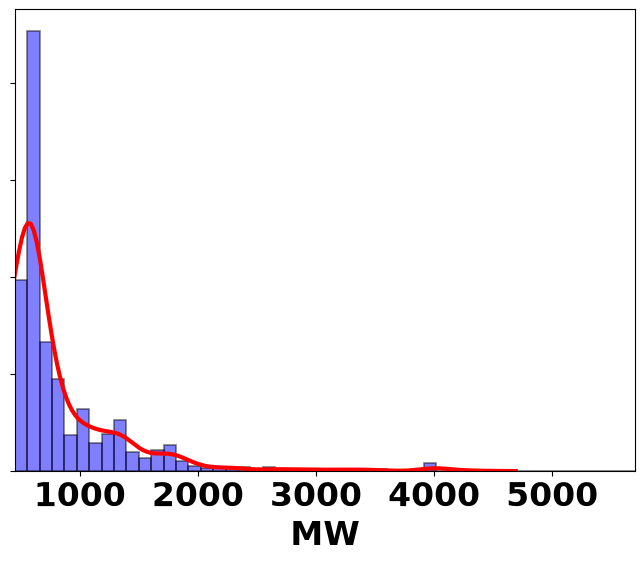

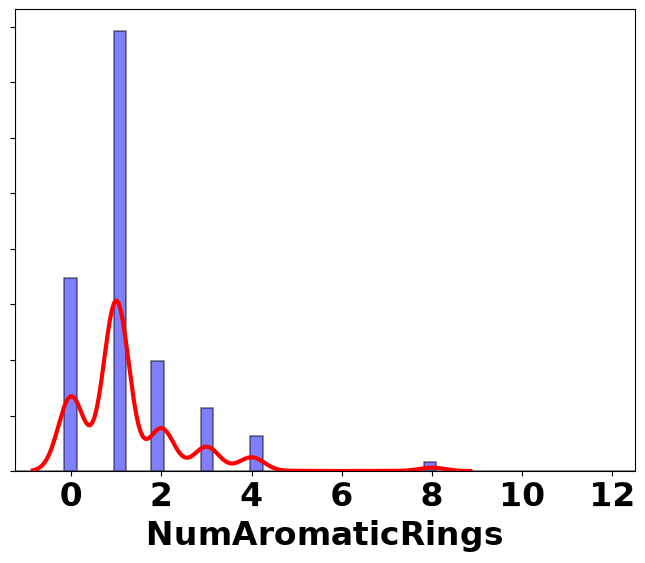

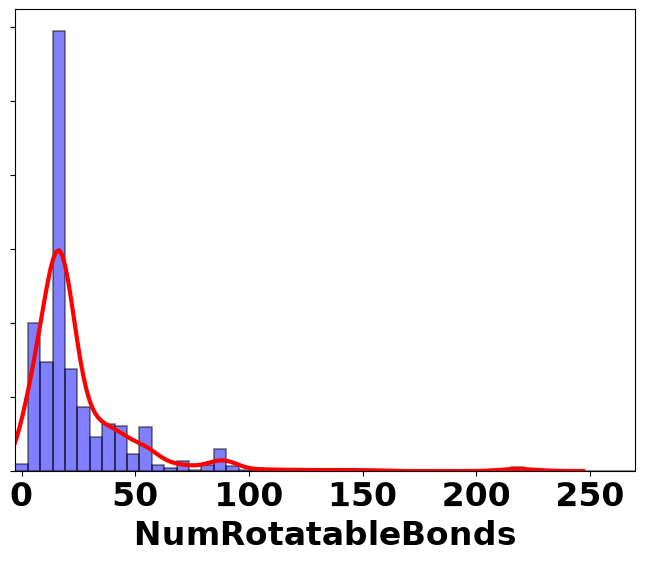

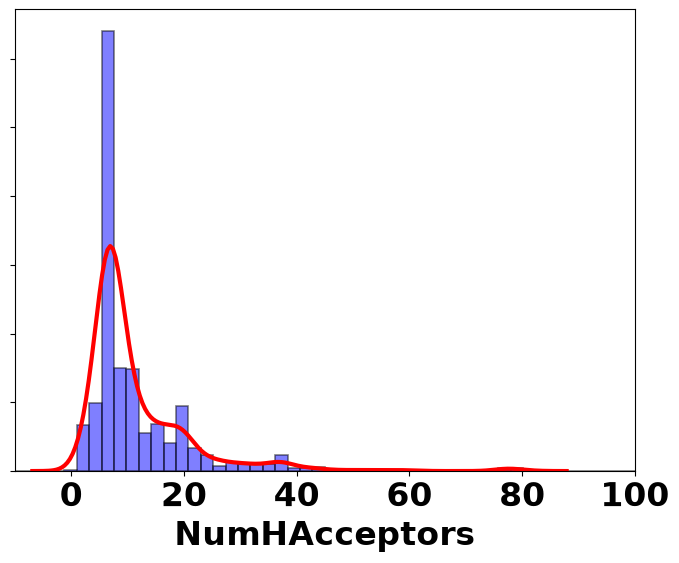

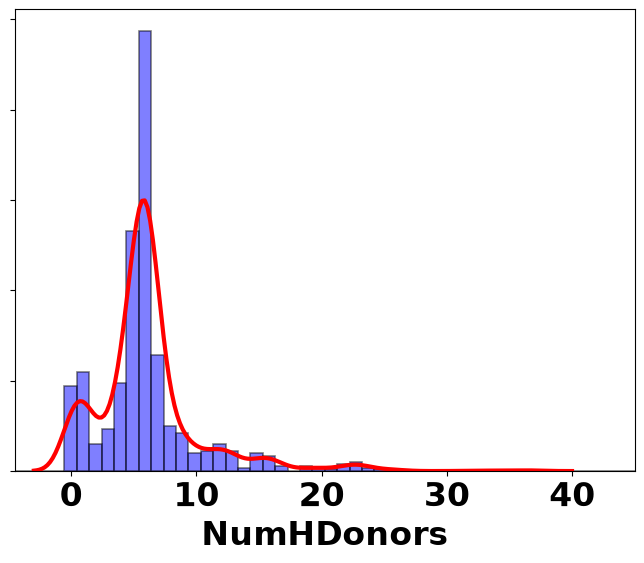

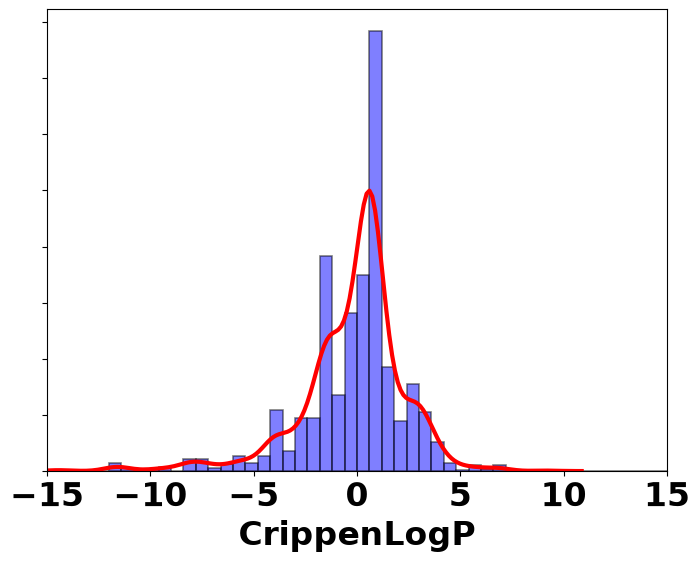

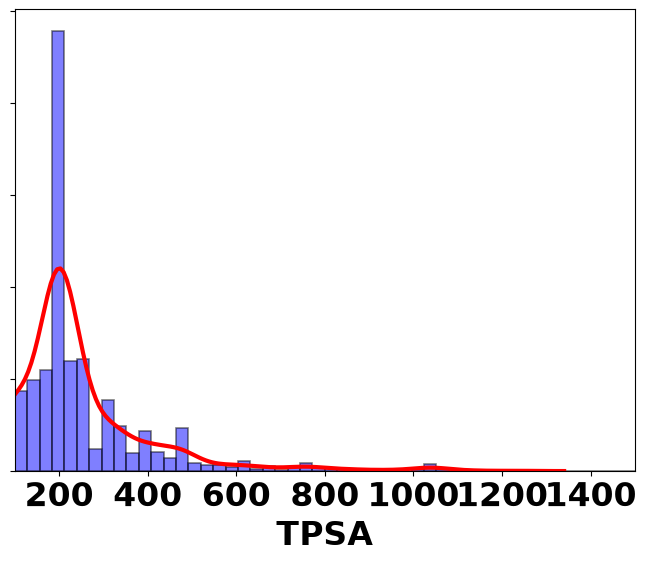

In [42]:
print(f"Maximum and minimum MW: {linker_df.MW.max()}, {linker_df.MW.min()}")
print(f"Maximum and minimum NumAromaticRings: {linker_df.NumAromaticRings.max()}, {linker_df.NumAromaticRings.min()}")
print(f"Maximum and minimum NumRotatableBonds: {linker_df.NumRotatableBonds.max()}, {linker_df.NumRotatableBonds.min()}")
print(f"Maximum and minimum NumHAcceptors: {linker_df.NumHAcceptors.max()}, {linker_df.NumHAcceptors.min()}")
print(f"Maximum and minimum NumHDonors: {linker_df.NumHDonors.max()}, {linker_df.NumHDonors.min()}")
print(f"Maximum and minimum CrippenLogP: {linker_df.CrippenLogP.max()}, {linker_df.CrippenLogP.min()}")
print(f"Maximum and minimum TPSA: {linker_df.TPSA.max()}, {linker_df.TPSA.min()}")
plot_histogram(df=linker_df, key="MW", factor=1, log=False, xlim_bottom=450, xlim_top=5700)
plot_histogram(df=linker_df, key="NumAromaticRings", factor=1.0, log=False, xlim_bottom=-1.25, xlim_top=12.5)
plot_histogram(df=linker_df, key="NumRotatableBonds", factor=1.0, log=False, xlim_bottom=-2.70, xlim_top=270)
plot_histogram(df=linker_df, key="NumHAcceptors", factor=1.0, log=False, xlim_bottom=-10, xlim_top=100)
plot_histogram(df=linker_df, key="NumHDonors", factor=1.0, log=False, xlim_bottom=-4.5, xlim_top=45)
plot_histogram(df=linker_df, key="CrippenLogP", factor=1.0, log=False, xlim_bottom=-15, xlim_top=15)
plot_histogram(df=linker_df, key="TPSA", factor=1, log=False, xlim_bottom=100, xlim_top=1500)

Number of clinical ADCs: 239
Number of non-clinical ADCs: 1293


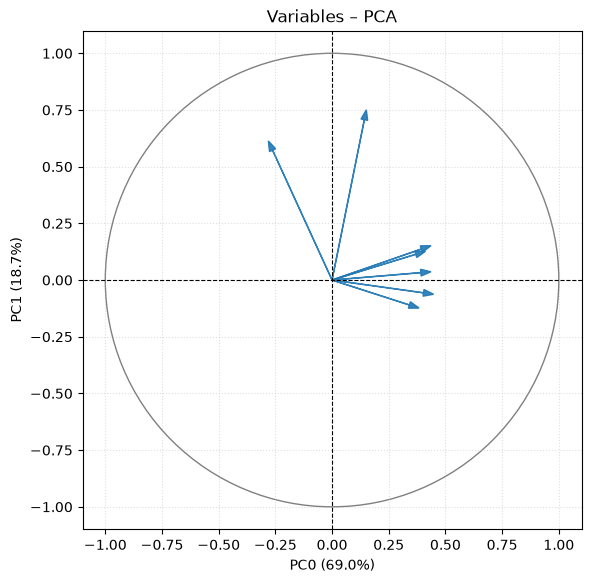

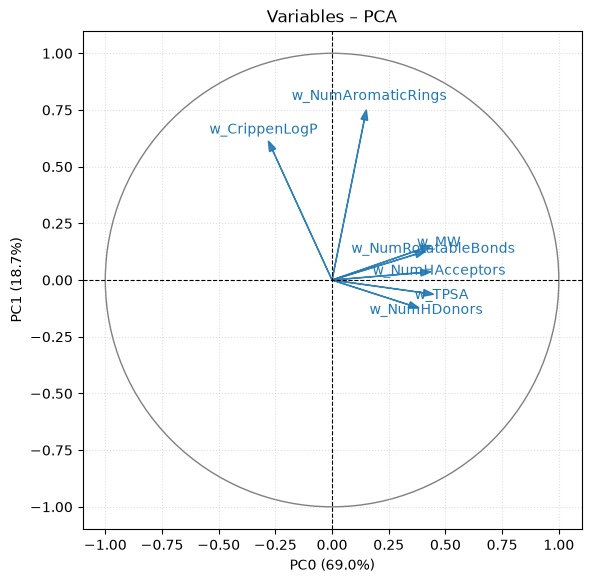

     w_NumAromaticRings  w_NumHAcceptors  w_NumHDonors  w_NumRotatableBonds  \
PC0            0.151219         0.436207      0.383732             0.412133   
PC1            0.751051         0.036431     -0.123638             0.126821   
PC2            0.476692        -0.305420      0.552718            -0.482859   
PC3           -0.351342        -0.040079      0.681013             0.184932   
PC4            0.244626         0.147483      0.093122             0.533660   
PC5            0.005624         0.830143      0.008445            -0.473716   
PC6            0.050058        -0.051182     -0.243812             0.193673   

         w_MW    w_TPSA  w_CrippenLogP  
PC0  0.436261  0.447761      -0.280960  
PC1  0.151537 -0.062619       0.613466  
PC2 -0.202301  0.121252      -0.291899  
PC3 -0.203478 -0.035072       0.578222  
PC4 -0.500381 -0.516136      -0.328884  
PC5 -0.269323 -0.053873       0.104477  
PC6 -0.617631  0.714394       0.078066  
69.02517129530199


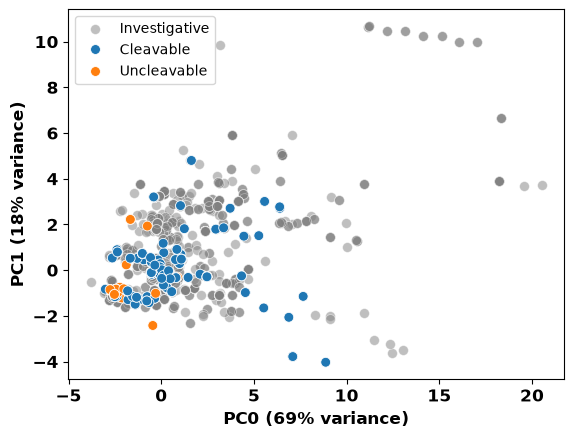

In [43]:
linker_clinical_df=linker_df[linker_df.adc_clinical==True].reset_index(drop=True)
print(f"Number of clinical ADCs: {len(linker_clinical_df)}")
linker_nonclinical_df=linker_df[linker_df.adc_clinical==False].reset_index(drop=True)
print(f"Number of non-clinical ADCs: {len(linker_nonclinical_df)}")
linker_pca_training=PCAresult(linker_clinical_df,feature_keys=DESCRIPTOR_KEYS)
linker_pca_training.plot_pca_loadings(arrow_labels=False)
linker_pca_training.plot_pca_loadings(arrow_labels=True)
print(linker_pca_training.loadings_df)
print(linker_pca_training.explained_variance_df.VarPerc.iloc[0])

df_pca_training=pd.concat([linker_clinical_df,linker_pca_training.components_df],axis=1)
df_pca_test=pd.concat([linker_nonclinical_df,linker_pca_training.project_dataframe(linker_nonclinical_df)],axis=1)
df_pca=pd.concat([df_pca_training,df_pca_test],axis=0).reset_index(drop=True)
sns.scatterplot(data=df_pca[df_pca.adc_maxphase=="Investigative"], x="PC0", y="PC1", color="gray", s=50,alpha=0.5, label="Investigative")
sns.scatterplot(data=df_pca[df_pca.adc_clinical==True], x="PC0", y="PC1", hue="linker_type", s=50,alpha=1.0,legend=True)

#sns.scatterplot(data=df_pca[df_pca.adc_maxphase=="Investigative"], x="PC0", y="PC1", color="gray", s=50,alpha=0.5, label="Investigative")
#sns.scatterplot(data=df_pca[(df_pca.adc_maxphase=="Phase 1") & (df_pca.adc_terminated==False)], x="PC0", y="PC1", color="purple", s=50,alpha=0.5, label="Phase 1")
#sns.scatterplot(data=df_pca[(df_pca.adc_maxphase=="Phase 2") & (df_pca.adc_terminated==False)], x="PC0", y="PC1", color="blue", s=50,alpha=0.5, label="Phase 2")
#sns.scatterplot(data=df_pca[(df_pca.adc_maxphase=="Phase 3") & (df_pca.adc_terminated==False)], x="PC0", y="PC1", color="orange", s=50,alpha=0.5, label="Phase 3")
#sns.scatterplot(data=df_pca[df_pca.adc_maxphase=="Approved"], x="PC0", y="PC1", color="green", s=50,alpha=1., label="Approved")
#sns.scatterplot(data=df_pca[df_pca.adc_terminated==True], x="PC0", y="PC1", color="red", s=50,alpha=1., label="Terminated")
plt.xticks(fontsize=12,fontweight="bold")
plt.yticks(fontsize=12,fontweight="bold")
plt.xlabel(f"PC0 ({int(linker_pca_training.explained_variance_df.VarPerc.iloc[0])}% variance)",fontsize=12,fontweight="bold")
plt.ylabel(f"PC1 ({int(linker_pca_training.explained_variance_df.VarPerc.iloc[1])}% variance)",fontsize=12,fontweight="bold")
plt.legend()
plt.show()
plt.close()

# Payload Analysis

In [44]:
descriptors=pd.DataFrame([basic_descriptors_from_smiles(smiles) for smiles in df.payload_smiles])
print(descriptors.head())
payload_df=pd.concat([df, descriptors], axis=1)

   NumAromaticRings  NumHAcceptors  NumHDonors  NumRotatableBonds       MW  \
0                 1              8           4                 21  731.976   
1                 3              7           3                  3  493.491   
2                 1              8           4                 20  717.993   
3                 1              8           4                 20  717.993   
4                 1             11           3                  7  738.300   

     TPSA  CrippenLogP  
0  166.61      3.10360  
1  130.75      1.62292  
2  149.54      3.52980  
3  149.54      3.52980  
4  156.47      3.83440  


In [45]:
print(max(payload_df.MW))

1580.5929999999992


Maximum and minimum MW: 1580.5929999999992, 233.097
Maximum and minimum NumAromaticRings: 6, 0
Maximum and minimum NumRotatableBonds: 31, 1
Maximum and minimum NumHAcceptors: 30, 3
Maximum and minimum NumHDonors: 13, 0
Maximum and minimum CrippenLogP: 8.34060000000001, -5.920200000000009
Maximum and minimum TPSA: 390.3000000000001, 76.53999999999999


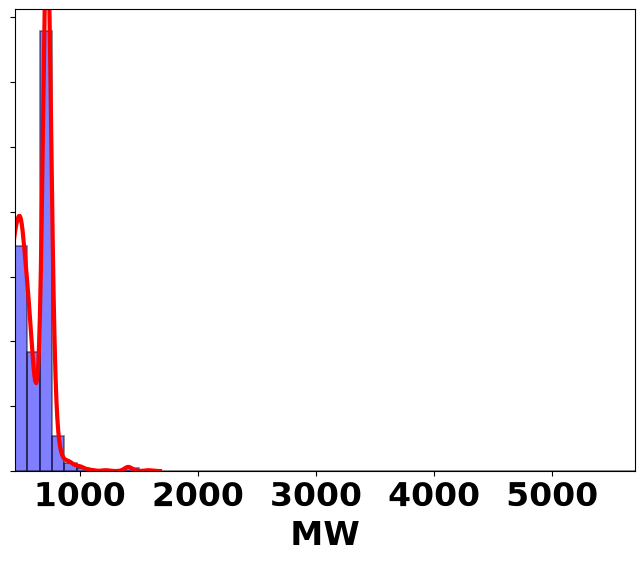

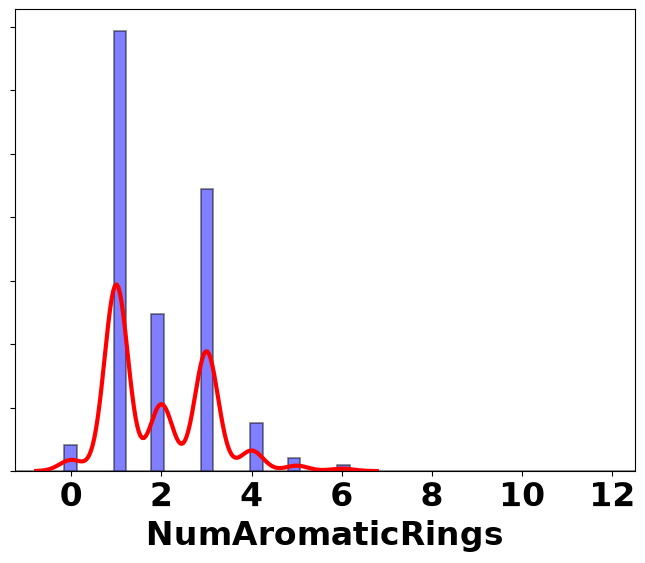

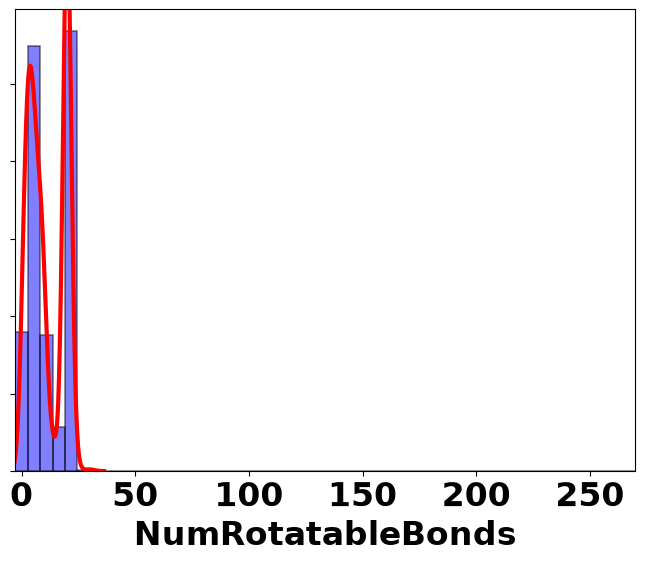

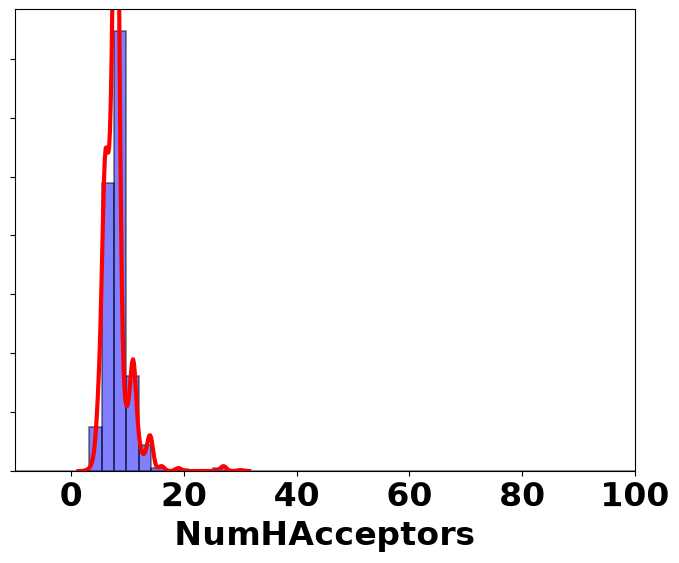

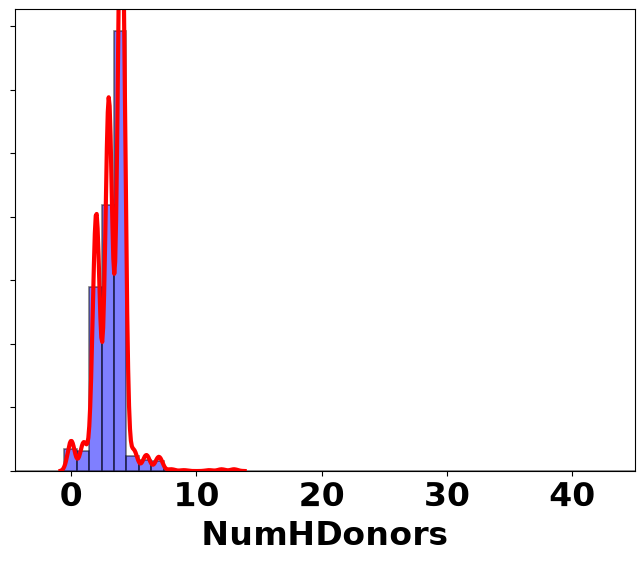

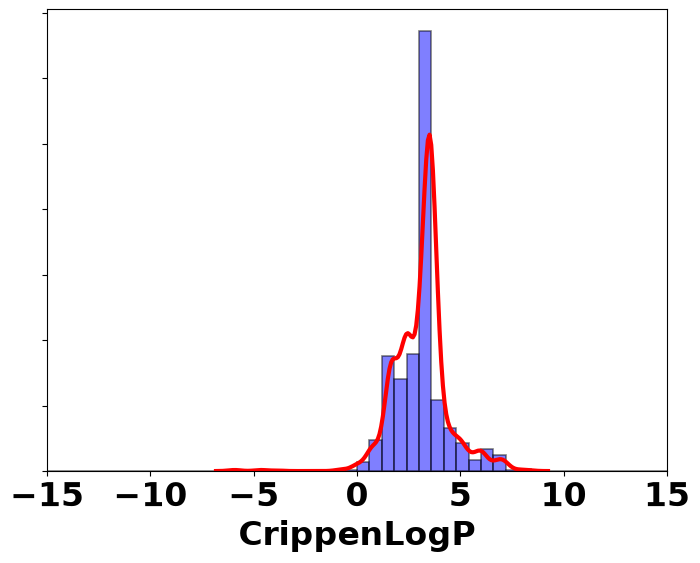

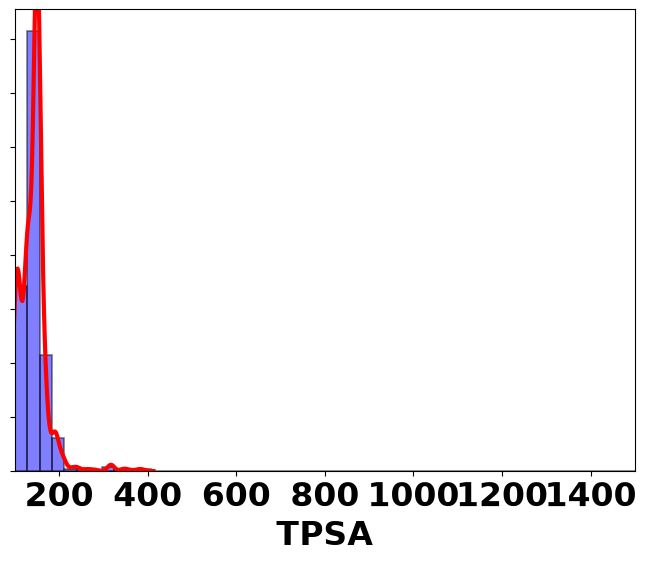

In [46]:
print(f"Maximum and minimum MW: {payload_df.MW.max()}, {payload_df.MW.min()}")
print(f"Maximum and minimum NumAromaticRings: {payload_df.NumAromaticRings.max()}, {payload_df.NumAromaticRings.min()}")
print(f"Maximum and minimum NumRotatableBonds: {payload_df.NumRotatableBonds.max()}, {payload_df.NumRotatableBonds.min()}")
print(f"Maximum and minimum NumHAcceptors: {payload_df.NumHAcceptors.max()}, {payload_df.NumHAcceptors.min()}")
print(f"Maximum and minimum NumHDonors: {payload_df.NumHDonors.max()}, {payload_df.NumHDonors.min()}")
print(f"Maximum and minimum CrippenLogP: {payload_df.CrippenLogP.max()}, {payload_df.CrippenLogP.min()}")
print(f"Maximum and minimum TPSA: {payload_df.TPSA.max()}, {payload_df.TPSA.min()}")
plot_histogram(df=payload_df, key="MW", factor=1, log=False, xlim_bottom=450, xlim_top=5700)
plot_histogram(df=payload_df, key="NumAromaticRings", factor=1.0, log=False, xlim_bottom=-1.25, xlim_top=12.5)
plot_histogram(df=payload_df, key="NumRotatableBonds", factor=1.0, log=False, xlim_bottom=-2.70, xlim_top=270)
plot_histogram(df=payload_df, key="NumHAcceptors", factor=1.0, log=False, xlim_bottom=-10, xlim_top=100)
plot_histogram(df=payload_df, key="NumHDonors", factor=1.0, log=False, xlim_bottom=-4.5, xlim_top=45)
plot_histogram(df=payload_df, key="CrippenLogP", factor=1.0, log=False, xlim_bottom=-15, xlim_top=15)
plot_histogram(df=payload_df, key="TPSA", factor=1, log=False, xlim_bottom=100, xlim_top=1500)

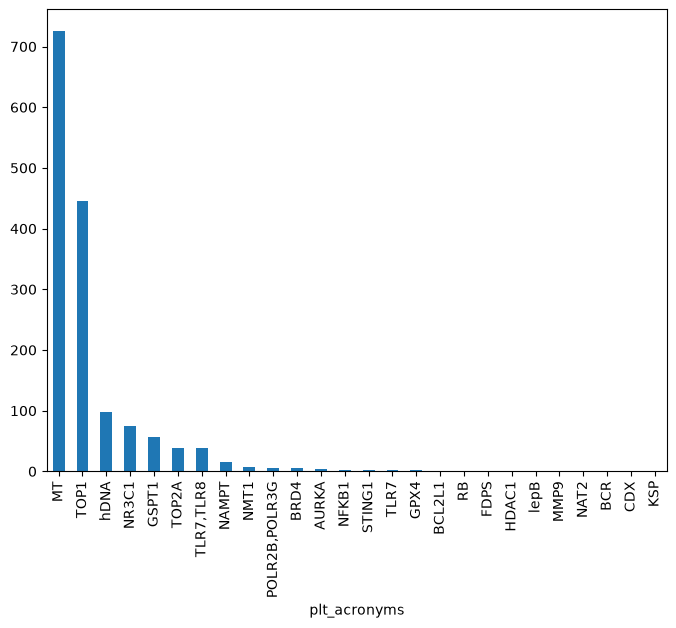

In [47]:
payload_df.plt_acronyms.value_counts().plot(kind="bar", figsize=(8,6))
plt.show()

Number of clinical ADCs: 239
Number of non-clinical ADCs: 1293


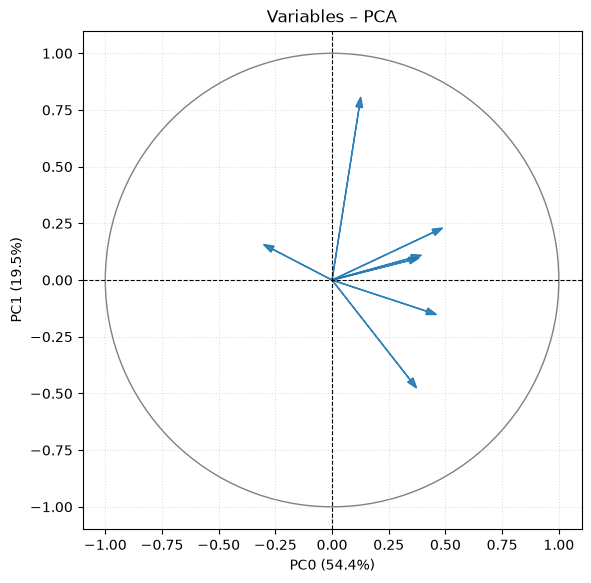

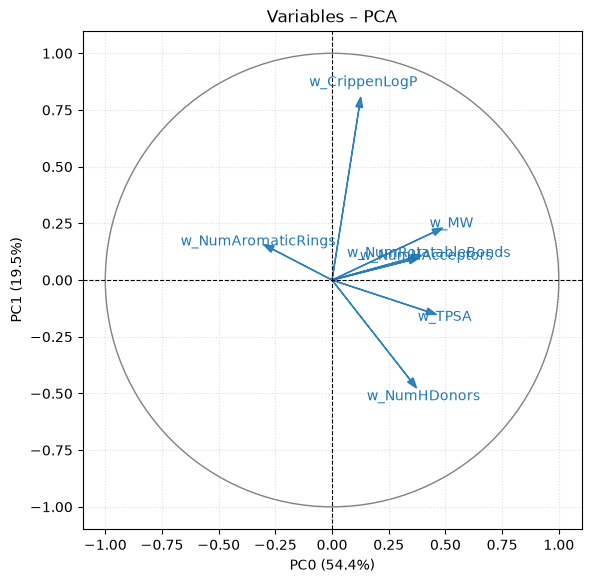

     w_NumAromaticRings  w_NumHAcceptors  w_NumHDonors  w_NumRotatableBonds  \
PC0           -0.302465         0.384228      0.372828             0.394452   
PC1            0.156946         0.097263     -0.476174             0.109834   
PC2            0.573250         0.554152     -0.032053            -0.496218   
PC3            0.695435        -0.387872      0.442991             0.372910   
PC4           -0.196951        -0.124336      0.600785            -0.596374   
PC5           -0.160112        -0.414358     -0.200919            -0.186852   
PC6            0.084923        -0.445228     -0.188884            -0.237642   

         w_MW    w_TPSA  w_CrippenLogP  
PC0  0.487875  0.460693       0.126612  
PC1  0.229741 -0.151848       0.807009  
PC2  0.058770  0.326126      -0.085017  
PC3 -0.027377  0.090867       0.147024  
PC4  0.064627 -0.189163       0.434956  
PC5 -0.262863  0.783640       0.210240  
PC6  0.794808  0.014672      -0.265470  
54.37145849114157


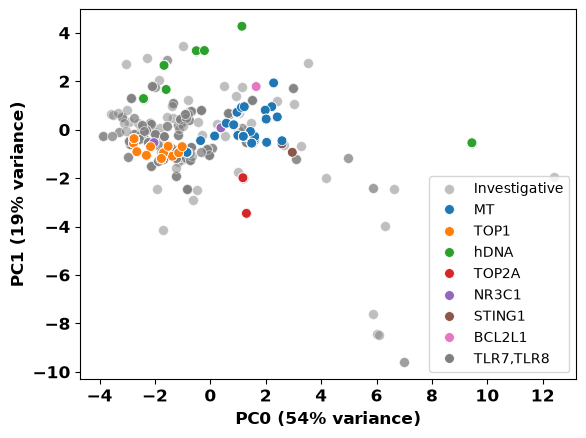

In [48]:
payload_clinical_df=payload_df[payload_df.adc_clinical==True].reset_index(drop=True)
print(f"Number of clinical ADCs: {len(payload_clinical_df)}")
payload_nonclinical_df=payload_df[payload_df.adc_clinical==False].reset_index(drop=True)
print(f"Number of non-clinical ADCs: {len(payload_nonclinical_df)}")
payload_pca_training=PCAresult(payload_clinical_df,feature_keys=DESCRIPTOR_KEYS)
payload_pca_training.plot_pca_loadings(arrow_labels=False)
payload_pca_training.plot_pca_loadings(arrow_labels=True)
print(payload_pca_training.loadings_df)
print(payload_pca_training.explained_variance_df.VarPerc.iloc[0])

df_pca_training=pd.concat([payload_clinical_df,payload_pca_training.components_df],axis=1)
df_pca_test=pd.concat([payload_nonclinical_df,payload_pca_training.project_dataframe(payload_nonclinical_df)],axis=1)
df_pca=pd.concat([df_pca_training,df_pca_test],axis=0).reset_index(drop=True)
sns.scatterplot(data=df_pca[df_pca.adc_maxphase=="Investigative"], x="PC0", y="PC1", color="gray", s=50,alpha=0.5, label="Investigative")
sns.scatterplot(data=df_pca[df_pca.adc_clinical==True], x="PC0", y="PC1", hue="plt_acronyms", s=50,alpha=1.0,legend=True)
#sns.scatterplot(data=df_pca[df_pca.adc_maxphase=="Investigative"], x="PC0", y="PC1", color="gray", s=50,alpha=0.5, label="Investigative")
#sns.scatterplot(data=df_pca[(df_pca.adc_maxphase=="Phase 1") & (df_pca.adc_terminated==False)], x="PC0", y="PC1", color="purple", s=50,alpha=0.5, label="Phase 1")
#sns.scatterplot(data=df_pca[(df_pca.adc_maxphase=="Phase 2") & (df_pca.adc_terminated==False)], x="PC0", y="PC1", color="blue", s=50,alpha=0.5, label="Phase 2")
#sns.scatterplot(data=df_pca[(df_pca.adc_maxphase=="Phase 3") & (df_pca.adc_terminated==False)], x="PC0", y="PC1", color="orange", s=50,alpha=0.5, label="Phase 3")
#sns.scatterplot(data=df_pca[df_pca.adc_maxphase=="Approved"], x="PC0", y="PC1", color="green", s=50,alpha=1., label="Approved")
#sns.scatterplot(data=df_pca[df_pca.adc_terminated==True], x="PC0", y="PC1", color="red", s=50,alpha=1., label="Terminated")
plt.xticks(fontsize=12,fontweight="bold")
plt.yticks(fontsize=12,fontweight="bold")
plt.xlabel(f"PC0 ({int(payload_pca_training.explained_variance_df.VarPerc.iloc[0])}% variance)",fontsize=12,fontweight="bold")
plt.ylabel(f"PC1 ({int(payload_pca_training.explained_variance_df.VarPerc.iloc[1])}% variance)",fontsize=12,fontweight="bold")
plt.legend()
plt.show()
plt.close()


In [49]:
from rdkit.Chem import AllChem, Draw
from wlp_chemspace.rdkit_utils import scaffold_from_smiles
murckos=set()
murckos_df=[]
for smiles in df.payload_smiles.unique():
    scaffold=scaffold_from_smiles(smiles, scaffold_type="rdkit")
    if scaffold is not None and scaffold not in murckos:
        murckos.add(scaffold)
        murckos_df.append(scaffold)
print(f"Found {len(murckos)} murcko scaffolds from {len(df)} molecules.")
df["murcko_scaffold"]=df.payload_smiles.apply(lambda x: Chem.MolToSmiles(scaffold_from_smiles(x, scaffold_type="rdkit"),canonical=True, isomericSmiles=True))

Found 212 murcko scaffolds from 1532 molecules.


<Axes: >

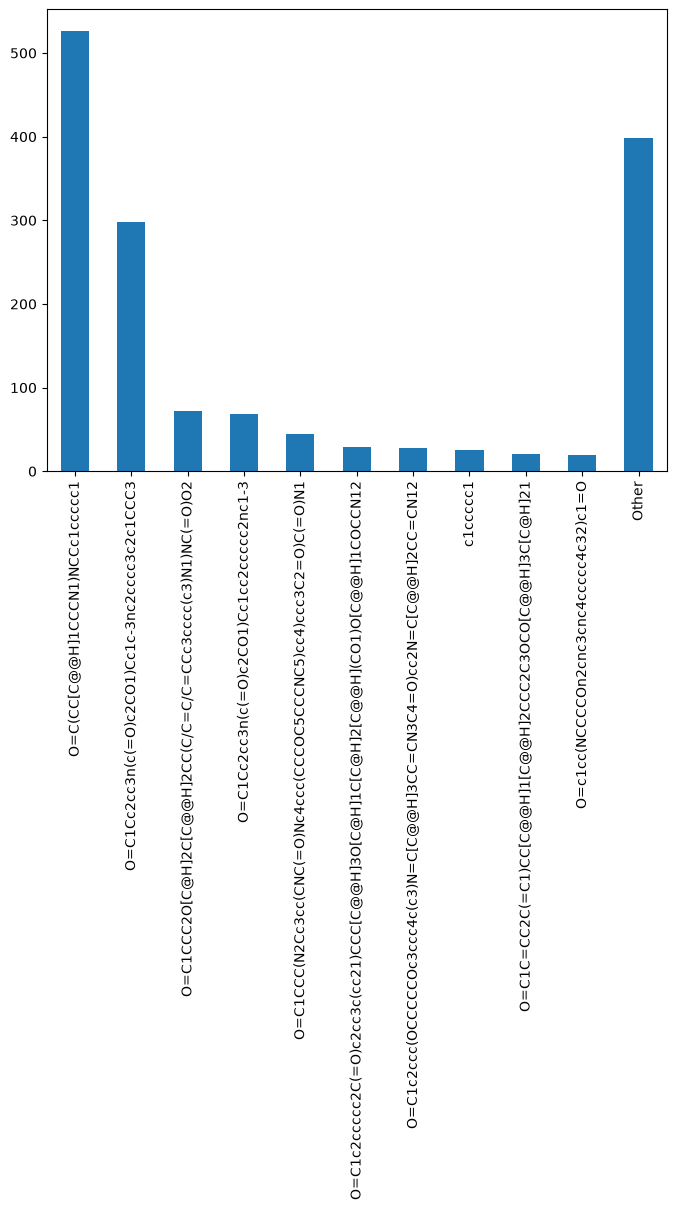

In [50]:
counts = df.murcko_scaffold.value_counts()
top10 = counts.head(10)
other = counts.iloc[10:].sum()
plot_counts = pd.concat([
    top10,
    pd.Series({"Other": other})
])
plot_counts.plot(kind="bar", figsize=(8,6))


/var/folders/n3/6vxjv07d3lbfbcgw0ql6dcw80000gr/T/ipykernel_53952/3990204397.py:21: DeprecationWarning: Image.Image.getdata is deprecated and will be removed in Pillow 14 (2027-10-15). Use get_flattened_data instead.
  for r, g, b, a in img.getdata():


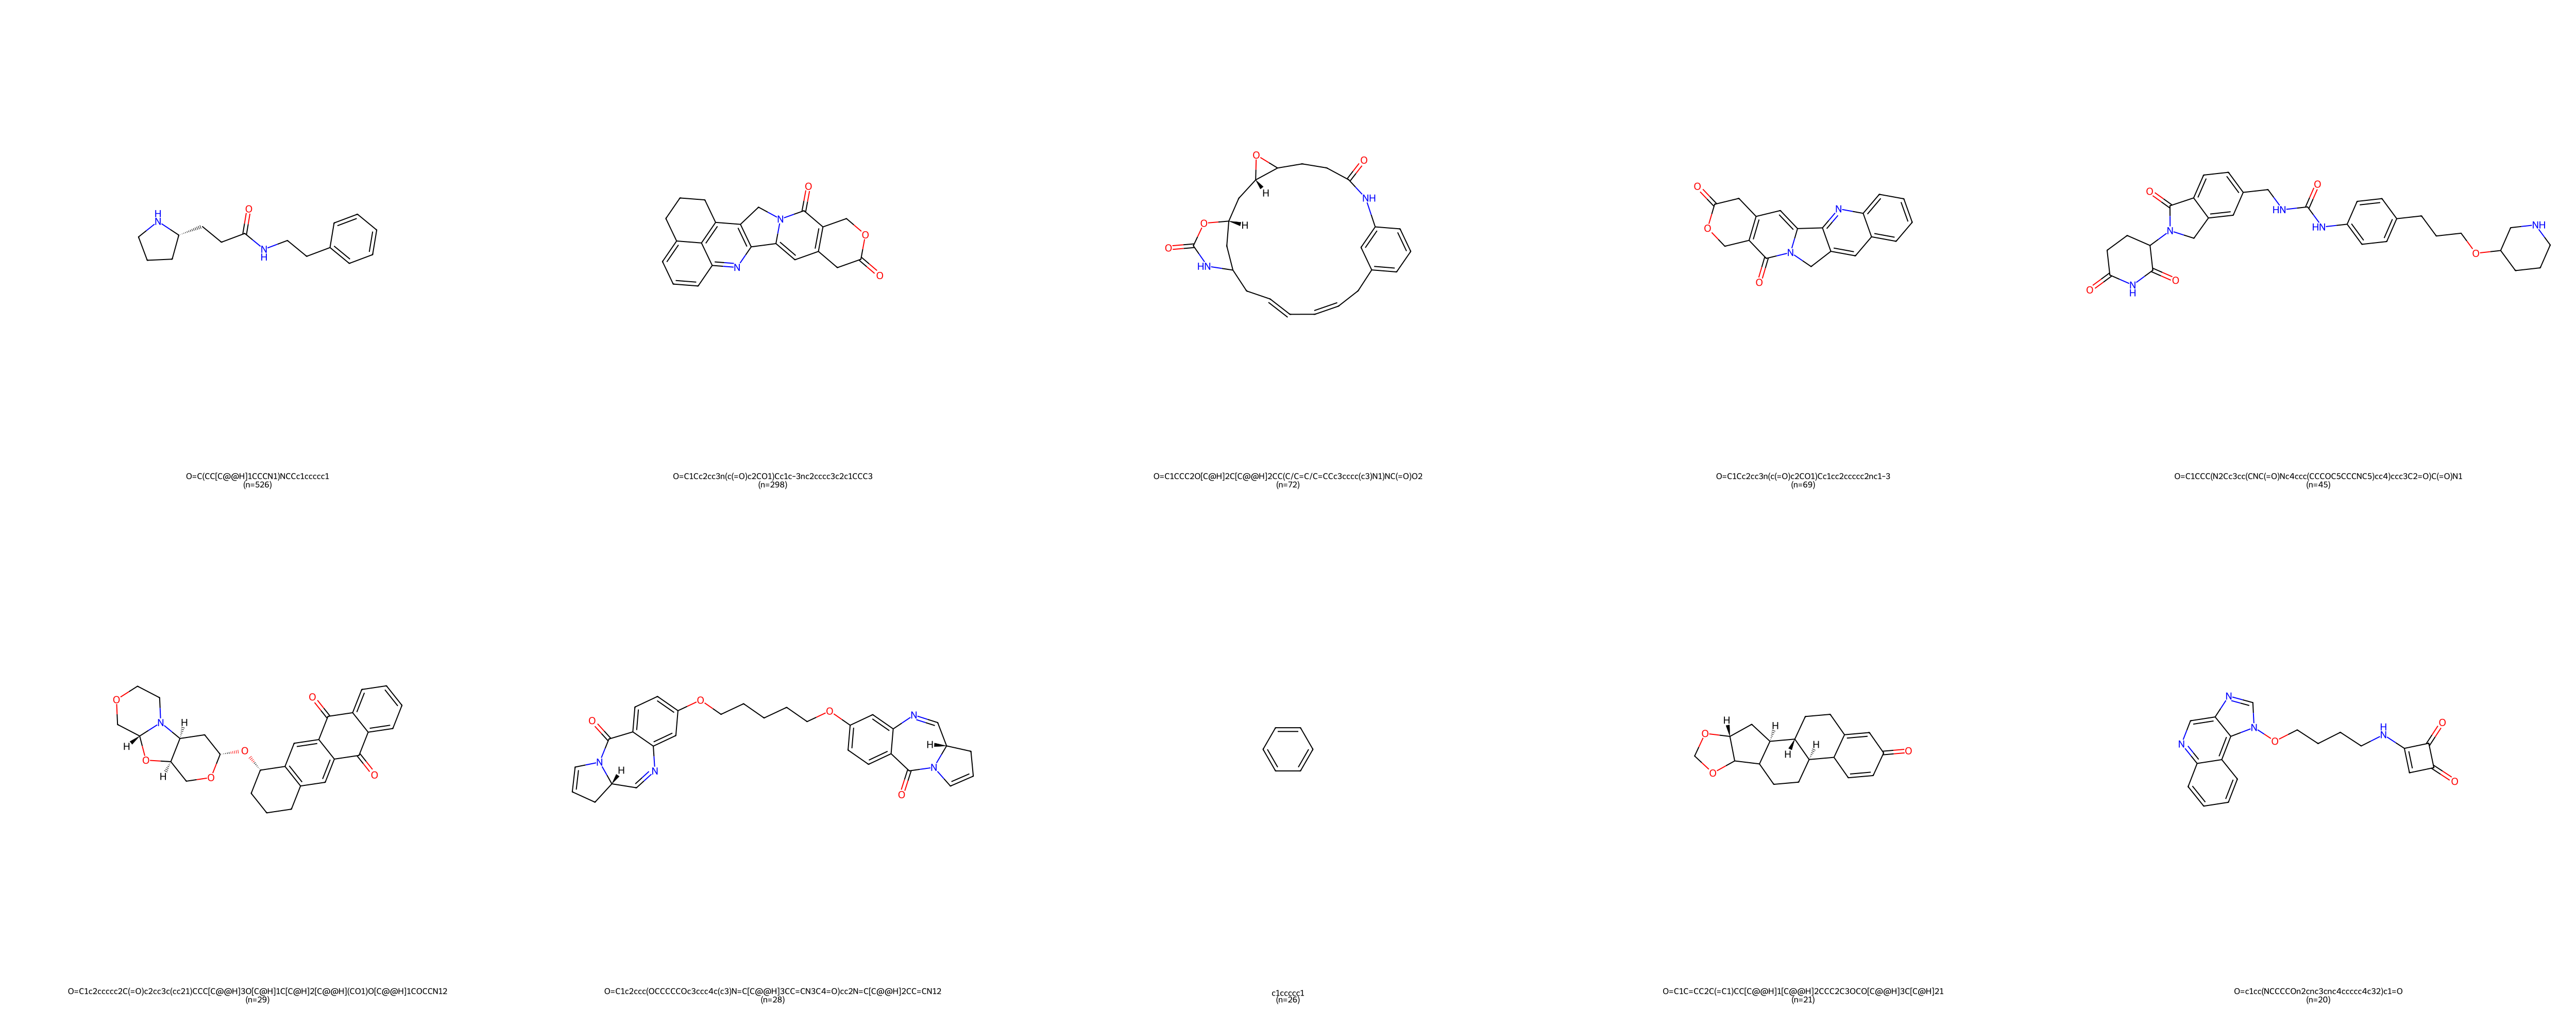

In [51]:
from rdkit.Chem import Draw

mols=[]
for scaffold in df.murcko_scaffold.value_counts().head(10).index:
    mol = Chem.MolFromSmiles(scaffold)
    if mol is not None:
        mols.append(mol)

legends = [f"{smi}\n(n={count})" for smi, count in counts.items()]


img = Draw.MolsToGridImage(
    mols,
    molsPerRow=5,
    subImgSize=(1000, 1000),
    legends=legends,
    returnPNG=False
)
img = img.convert("RGBA")
data = []
for r, g, b, a in img.getdata():
    if (r, g, b) == (255, 255, 255): # white background
       data.append((255, 255, 255, 0))
    else:
       data.append((r, g, b, a))

img.putdata(data)
img

<Axes: xlabel='payload_class'>

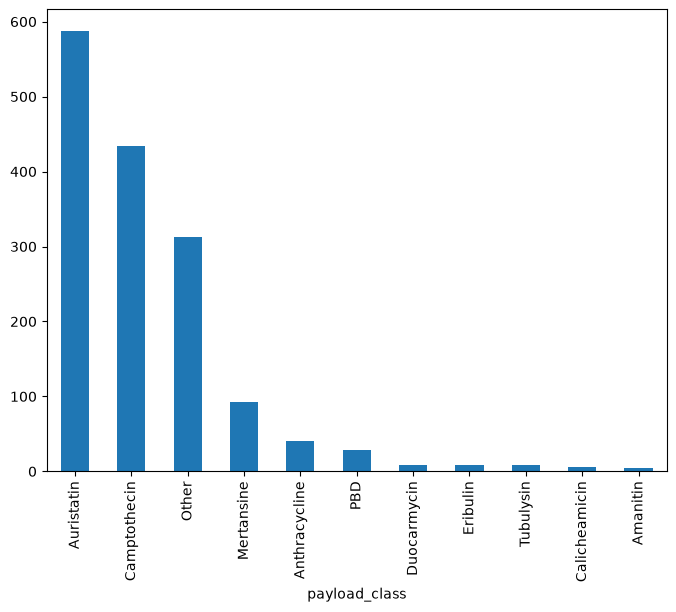

In [52]:
counts = df.payload_class.value_counts()
counts.plot(kind="bar", figsize=(8,6))

# JQ-1 and kinase Dataset

In [53]:
msdata=pd.read_csv("../.data/Master_Data_PP_20261016.csv").drop(columns=["MW"]).dropna(subset=["SMILES"]).drop_duplicates(subset=["SMILES"]).reset_index(drop=True)
descriptors=pd.DataFrame([basic_descriptors_from_smiles(smiles) for smiles in msdata.SMILES])
msdata=pd.concat([msdata, descriptors], axis=1)
msdata

,Reaction code,name,warhead,spacer1,linker,spacer2,payload,SMILES,cleavable?,Cleavage enzyme (targeted),...,ChromLogD,Failed?,Reason,NumAromaticRings,NumHAcceptors,NumHDonors,NumRotatableBonds,MW,TPSA,CrippenLogP
0,AVJ-003,Mal-dansyl,maleimide,CC,6C,5C,dansyl,CN(C)C1=C(C=CC=C2S(=O)(NCCCCCNC(CCCCCNC(C3CCC(...,No,NaN,...,NaN,NaN,NaN,2,7,3,18,667.873,144.99,3.87860
1,AVJ-052,Mc-cbGly-Cit-PABA-JQ1,maleimide,6C,cbGly-Cit,PABA,JQ1-amine,O=C(C=C1)N(CCCCCC(NC2(CCC2)C(N[C@H](C(NC3=CC=C...,Yes,Cathepsin B,...,NaN,NaN,NaN,4,13,7,23,1039.617,290.30,4.62836
2,AVJ-053,Mc-cbGly-Cit-PABA-exatecan,maleimide,6C,cbGly-Cit,PABA,exatecan,O=C(NC1(CCC1)C(N[C@H](C(NC2=CC=C(COC(N[C@@H](C...,Yes,Cathepsin B,...,NaN,NaN,NaN,4,13,7,19,1032.096,299.55,3.83692
3,AVJ-056,Mc-Val-Val-PABA-JQ1,maleimide,6C,Val-Val,PABA,JQ1-amine,CC(C)[C@@H](C(NC1=CC=C(COC(NCCNC(C[C@@H](C2=NN...,Yes,Cathepsin B,...,NaN,NaN,NaN,4,12,5,21,983.593,235.18,5.93776
4,AVJ-057,Mc-Val-Val-PABA-exatecan,maleimide,6C,Val-Val,PABA,exatecan,CC(C)[C@@H](C(NC1=CC=C(COC(N[C@@H](CCC2=C3C(N=...,Yes,Cathepsin B,...,NaN,Yes,Product not recoverable,4,12,5,17,976.072,244.43,5.14632
5,AVJ-060,Mc-Ala-Glu(tBu)-PABA-exatecan,maleimide,6C,Ala-Glu(tBu),PABA,exatecan,O=C(NC1=CC=C(COC(N[C@@H](CCC2=C3C(N=C4C5=C6)=C...,Yes,Cathepsin B,...,NaN,Yes,Product not isolated,4,14,5,18,1034.108,270.73,4.97612
6,AVJ-068,Mc-Gly-Gly-Phe-PABA-exatecan,maleimide,6C,Gly-Gly-Phe,PABA,exatecan,O=C(NC1=CC=C(COC(N[C@@H](CCC2=C3C(N=C4C5=C6)=C...,Yes,Cathepsin B,...,NaN,Yes,NaN,5,13,6,19,1039.087,273.53,3.82462
7,AVJ-069,Mc-Asn-Asn-PABA-exatecan,maleimide,6C,Asn-Asn,PABA,exatecan,O=C(N[C@@H](CCC1=C2C(N=C3C4=C5)=CC(F)=C1C)C2=C...,Yes,Cathepsin B,...,NaN,Yes,NaN,4,14,7,19,1006.014,330.61,1.58512
8,AVJ-073,Mc-Ala-Glu-PABA-JQ1,maleimide,6C,Ala-Glu,PABA,JQ1-amine,O=C(C=C1)N(CCCCCC(N[C@H](C(N[C@H](C(NC2=CC=C(C...,Yes,Cathepsin B,...,NaN,NaN,NaN,4,13,6,22,985.521,272.48,4.51046
9,AVJ-080,Mc-Ala-Gln-PABA-JQ1,maleimide,6C,Ala-Gln,PABA,JQ1-amine,O=C(C=C1)N(CCCCCC(N[C@H](C(N[C@@H](CCC(N)=O)C(...,Yes,Cathepsin B,...,NaN,NaN,NaN,4,13,6,22,984.537,278.27,3.91116


# Aidan's Oct 26 click chemistry library 

In [54]:
click1026=pd.read_csv("../.data/2610_click.csv")
click1026_descriptors=pd.DataFrame([basic_descriptors_from_smiles(smiles) for smiles in click1026.SMILES])
click1026=pd.concat([click1026, click1026_descriptors], axis=1)
click1026
#sns.barplot(data=click1026, x="payload", y="MW")

,Base linker,Base_linker_3L,payload,solubilising group,Name,SMILES,NumAromaticRings,NumHAcceptors,NumHDonors,NumRotatableBonds,MW,TPSA,CrippenLogP
0,"Mc-N3KGNN, N3LysAsnAsn",N3LysAsnAsn,JQ1-amine,mPEG2,Mc-KPEG2GNN-JQ1-amine,O=C(CNC([C@H](CCCCN1N=NC(COCCOCCOC)=C1)NC(CCCC...,4,19,8,37,1233.808,399.63,-0.12954
1,NaN,N3LysAsnAsn,crizotinib,mPEG2,Mc-KPEG2GNN-crizotinib,C[C@@H](OC1=C(N)N=CC(C2=CN(C3CCN(C([C@H](CC(N)...,4,18,7,36,1241.177,384.63,1.72510
2,NaN,N3LysAsnAsn,palbociclib,mPEG2,Mc-KPEG2GNN-palbociclib,CC1=C(C(C)=O)C(N(C2CCCC2)C3=NC(NC4=NC=C(N5CCN(...,4,21,7,36,1238.375,411.68,-0.34678
3,NaN,N3LysAsnAsn,ribociclib,mPEG2,Mc-KPEG2GNN-ribociclib,CN(C(C1=CC2=CN=C(NC3=NC=C(N4CCN(C([C@H](CC(N)=...,4,20,7,36,1225.380,397.85,-0.51620
4,NaN,N3LysAsnAsn,JQ1-amine,mPEG3,Mc-KPEG3GNN-JQ1-amine,O=C(CNC([C@H](CCCCN1N=NC(COCCOCCOCCOC)=C1)NC(C...,4,20,8,40,1277.861,408.86,-0.11294
5,NaN,N3LysAsnAsn,crizotinib,mPEG3,Mc-KPEG3GNN-crizotinib,C[C@@H](OC1=C(N)N=CC(C2=CN(C3CCN(C([C@H](CC(N)...,4,19,7,39,1285.230,393.86,1.74170
6,NaN,N3LysAsnAsn,palbociclib,mPEG3,Mc-KPEG3GNN-palbociclib,CC1=C(C(C)=O)C(N(C2CCCC2)C3=NC(NC4=NC=C(N5CCN(...,4,22,7,39,1282.428,420.91,-0.33018
7,NaN,N3LysAsnAsn,ribociclib,mPEG3,Mc-KPEG3GNN-ribociclib,CN(C(C1=CC2=CN=C(NC3=NC=C(N4CCN(C([C@H](CC(N)=...,4,21,7,39,1269.433,407.08,-0.49960
8,NaN,N3LysAsnAsn,JQ1-amine,mPEG4,Mc-KPEG4GNN-JQ1-amine,O=C(CNC([C@H](CCCCN1N=NC(COCCOCCOCCOCCOC)=C1)N...,4,21,8,43,1321.914,418.09,-0.09634
9,NaN,N3LysAsnAsn,crizotinib,mPEG4,Mc-KPEG4GNN-crizotinib,C[C@@H](OC1=C(N)N=CC(C2=CN(C3CCN(C([C@H](CC(N)...,4,20,7,42,1329.283,403.09,1.75830


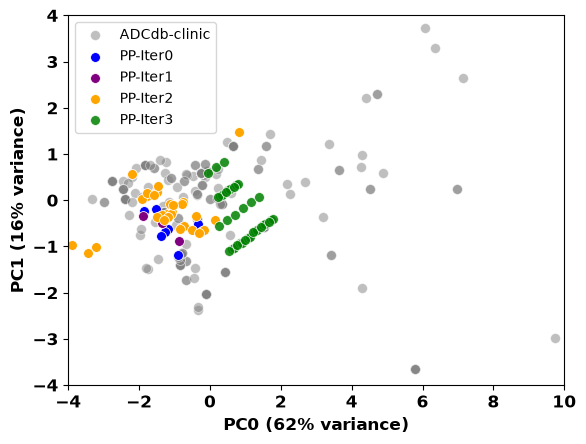

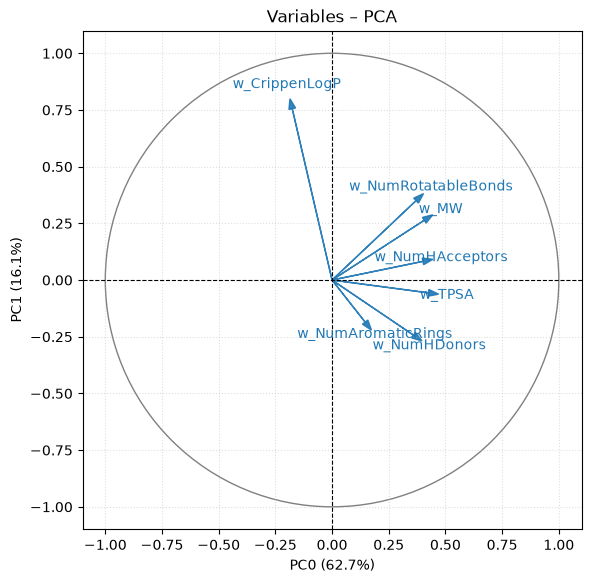

     w_NumAromaticRings  w_NumHAcceptors  w_NumHDonors  w_NumRotatableBonds  \
PC0            0.173820         0.444813      0.396298             0.403230   
PC1           -0.220857         0.091491     -0.268114             0.381178   
PC2            0.936652         0.010329     -0.139705            -0.163390   
PC3            0.006501        -0.415740      0.796893            -0.052114   
PC4            0.203282        -0.458088     -0.081705             0.786288   
PC5            0.046085         0.640232      0.236194             0.192322   
PC6           -0.014195         0.032917     -0.232470             0.086375   

         w_MW    w_TPSA  w_CrippenLogP  
PC0  0.444221  0.469526      -0.185727  
PC1  0.287984 -0.062268       0.799286  
PC2  0.040674 -0.029286       0.271753  
PC3 -0.152853  0.067171       0.401855  
PC4 -0.169847 -0.184579      -0.246964  
PC5 -0.539759 -0.443068       0.086919  
PC6 -0.611986  0.734793       0.150881  


In [78]:
wlp_df_pca_training=pd.concat([wlp_clinical_df,wlp_pca_training.components_df],axis=1)
inhouse_pca_test=pd.concat([msdata,wlp_pca_training.project_dataframe(msdata)],axis=1)
inhouse_pca=pd.concat([wlp_df_pca_training,inhouse_pca_test],axis=0).reset_index(drop=True)
click2610_pca_test=pd.concat([click1026,wlp_pca_training.project_dataframe(click1026)],axis=1)

ax=sns.scatterplot(data=inhouse_pca[inhouse_pca.adc_maxphase.isna()==False], x="PC0", y="PC1", color="gray", s=50,alpha=0.5, label="ADCdb-clinic")
sns.scatterplot(data=inhouse_pca[inhouse_pca.payload=="exatecan"], x="PC0", y="PC1", color="blue", s=50,alpha=1.0, label="PP-Iter0",ax=ax)
sns.scatterplot(data=inhouse_pca[inhouse_pca.payload=="JQ1-amine"], x="PC0", y="PC1", color="purple", s=50,alpha=1.0, label="PP-Iter1",ax=ax)
sns.scatterplot(data=inhouse_pca[(inhouse_pca.payload=="palbociclib") | (inhouse_pca.payload=="ribociclib") | (inhouse_pca.payload=="dasatinib") |
                                  (inhouse_pca.payload=="crizotinib") | (inhouse_pca.payload=="olaparib")            
                                ], x="PC0", y="PC1", color="orange", s=50,alpha=1.0, label="PP-Iter2",ax=ax)
sns.scatterplot(data=click2610_pca_test, x="PC0", y="PC1", color="green", s=50,alpha=0.85,ax=ax,label="PP-Iter3")
#annotate_plot(ax=ax, df=inhouse_pca[inhouse_pca.payload=="olaparib"], x="PC0", y="PC1", key="linker")

ax.set_xlim(-4, 10)
ax.set_ylim(-4, 4)
plt.xticks(fontsize=12,fontweight="bold")
plt.yticks(fontsize=12,fontweight="bold")
plt.xlabel(f"PC0 ({int(wlp_pca_training.explained_variance_df.VarPerc.iloc[0])}% variance)",fontsize=12,fontweight="bold")
plt.ylabel(f"PC1 ({int(wlp_pca_training.explained_variance_df.VarPerc.iloc[1])}% variance)",fontsize=12,fontweight="bold")
plt.show()
plt.close()

wlp_pca_training.plot_pca_loadings(arrow_labels=True)
print(wlp_pca_training.loadings_df)

In [56]:
kinase_payloads = [
    "palbociclib",
    "ribociclib",
    "dasatinib",
    "crizotinib",
    "olaparib"
]

inhouse_pca_kinase = inhouse_pca[
    inhouse_pca["payload"].isin(kinase_payloads)
]

inhouse_pca_jq1 = inhouse_pca[
    inhouse_pca["payload"] == "JQ1-amine"
]

inhouse_pca_exatecan = inhouse_pca[
    inhouse_pca["payload"] == "exatecan"]


In [57]:
wlp_df_pca_training[wlp_df_pca_training["PC0"] > 8][["adc_id","linker_name","payload_name","MW","NumAromaticRings","NumHAcceptors","NumHDonors","NumRotatableBonds","TPSA","CrippenLogP"]]


,adc_id,linker_name,payload_name,MW,NumAromaticRings,NumHAcceptors,NumHDonors,NumRotatableBonds,TPSA,CrippenLogP
79,DRG0KTTFS,Hydrophilic linker of XMT-2056,STING agonist,2357.422,6,47,25,87,932.58,-10.52316


CrippenLogP range for JQ1-amine payload: 2.3765600000000062 - 5.937760000000006
CrippenLogP range for kinase payloads: 1.2857000000000023 - 11.133199999999993
CrippenLogP range for exatecan payloads: 1.5851200000000067 - 5.146320000000005


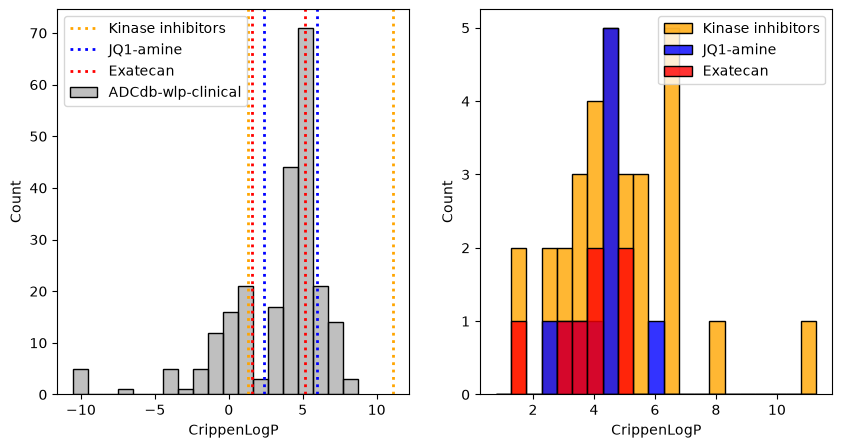

   Reaction code                         name    warhead spacer1  \
1        AVJ-052        Mc-cbGly-Cit-PABA-JQ1  maleimide      6C   
3        AVJ-056          Mc-Val-Val-PABA-JQ1  maleimide      6C   
8        AVJ-073          Mc-Ala-Glu-PABA-JQ1  maleimide      6C   
9        AVJ-080          Mc-Ala-Gln-PABA-JQ1  maleimide      6C   
12       AVJ-093          Mc-Ala-Ala-PABA-JQ1  maleimide      6C   
13       AVJ-094          Mc-Asn-Asn-PABA-JQ1  maleimide      6C   
14       AVJ-095          Mc-Val-Cit-PABA-JQ1  maleimide      6C   
15       AVJ-096  Mc-Gly-Gly-Phe-Gly-PABA-JQ1  maleimide      6C   
16       AVJ-098      Mc-Gly-Gly-Phe-PABA-JQ1  maleimide      6C   
17       AVJ-104      Mc-Glu-Gly-Cit-PABA-JQ1  maleimide      6C   

             linker spacer2    payload  \
1         cbGly-Cit    PABA  JQ1-amine   
3           Val-Val    PABA  JQ1-amine   
8           Ala-Glu    PABA  JQ1-amine   
9           Ala-Gln    PABA  JQ1-amine   
12          Ala-Ala    PABA  JQ1-amine   

In [58]:
descriptor="CrippenLogP"
binwidth_left=1
binwidth_right=0.5

min_descriptor_JQ1=inhouse_pca_jq1[descriptor].min()
max_descriptor_JQ1=inhouse_pca_jq1[descriptor].max()
min_descriptor_kinase=inhouse_pca_kinase[descriptor].min()
max_descriptor_kinase=inhouse_pca_kinase[descriptor].max()
min_descriptor_exatecan=inhouse_pca_exatecan[descriptor].min()
max_descriptor_exatecan=inhouse_pca_exatecan[descriptor].max()
print(f"{descriptor} range for JQ1-amine payload: {min_descriptor_JQ1} - {max_descriptor_JQ1}")
print(f"{descriptor} range for kinase payloads: {min_descriptor_kinase} - {max_descriptor_kinase}")
print(f"{descriptor} range for exatecan payloads: {min_descriptor_exatecan} - {max_descriptor_exatecan}")
maxmins=[min_descriptor_JQ1, max_descriptor_JQ1, min_descriptor_kinase, max_descriptor_kinase, min_descriptor_exatecan, max_descriptor_exatecan]

fig, ax = plt.subplots(1,2,figsize=(10,5))
sns.histplot(data=wlp_df_pca_training, x=descriptor, ax=ax[0],color="gray", label="ADCdb-wlp-clinical",alpha=0.5,binwidth=binwidth_left);
# Add red dotted vertical lines
ax[0].axvline(min_descriptor_kinase, color="orange", linestyle=":", linewidth=2,
              label=f"Kinase inhibitors")
ax[0].axvline(max_descriptor_kinase, color="orange", linestyle=":", linewidth=2,)
ax[0].axvline(min_descriptor_JQ1, color="blue", linestyle=":", linewidth=2,
              label=f"JQ1-amine")
ax[0].axvline(max_descriptor_JQ1, color="blue", linestyle=":", linewidth=2,)
ax[0].axvline(min_descriptor_exatecan, color="red", linestyle=":", linewidth=2,
              label=f"Exatecan")
ax[0].axvline(max_descriptor_exatecan, color="red", linestyle=":", linewidth=2,)

bins=np.arange(min(maxmins)-0.5, max(maxmins)+0.5, binwidth_right)
sns.histplot(data=inhouse_pca_kinase, x=descriptor, ax=ax[1], color="orange", label="Kinase inhibitors", bins=bins,alpha=0.8)
sns.histplot(data=inhouse_pca_jq1, x=descriptor, ax=ax[1], color="blue", label="JQ1-amine", bins=bins,alpha=0.8)
sns.histplot(data=inhouse_pca_exatecan, x=descriptor, ax=ax[1], color="red", label="Exatecan", bins=bins,alpha=0.8)
#sns.barplot(data=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"], x="linker", y=descriptor, ax=ax[1]);

#plt.xticks(rotation=90)
ax[0].legend()
ax[1].legend()
plt.show(); 
plt.close()
print(inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"])


NumAromaticRings range for JQ1-amine payload: 4 - 5


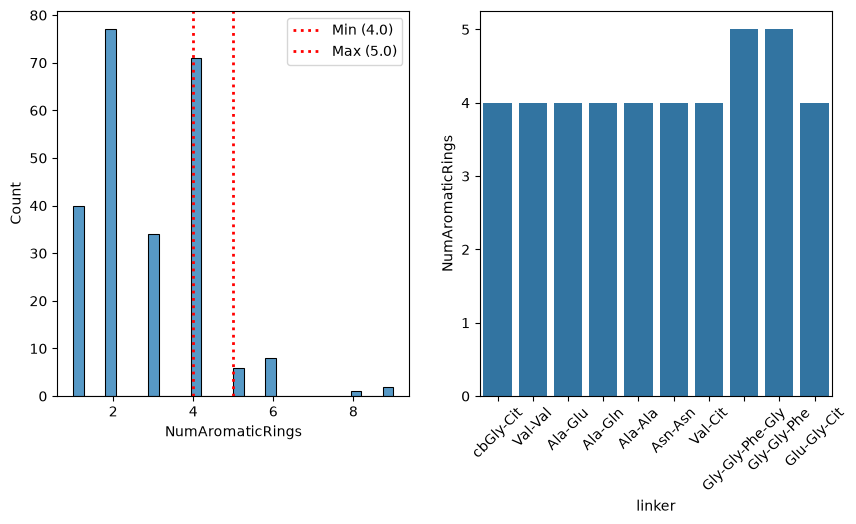

In [59]:
fig, ax = plt.subplots(1,2,figsize=(10,5))
descriptor="NumAromaticRings"
min_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"][descriptor].min()
max_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"][descriptor].max()
# Add red dotted vertical lines
ax[0].axvline(min_descriptor_inhouse, color="red", linestyle=":", linewidth=2,
              label=f"Min ({min_descriptor_inhouse:.1f})")
ax[0].axvline(max_descriptor_inhouse, color="red", linestyle=":", linewidth=2,
              label=f"Max ({max_descriptor_inhouse:.1f})")

ax[0].legend()
print(f"{descriptor} range for JQ1-amine payload: {min_descriptor_inhouse} - {max_descriptor_inhouse}")
sns.barplot(data=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"], x="linker", y=descriptor, ax=ax[1]);
sns.histplot(data=wlp_df_pca_training, x=descriptor, ax=ax[0],bins=30);
plt.xticks(rotation=45)
plt.show(); 
plt.close()

NumRotatableBonds range for JQ1-amine payload: 235.17999999999995 - 356.69999999999993


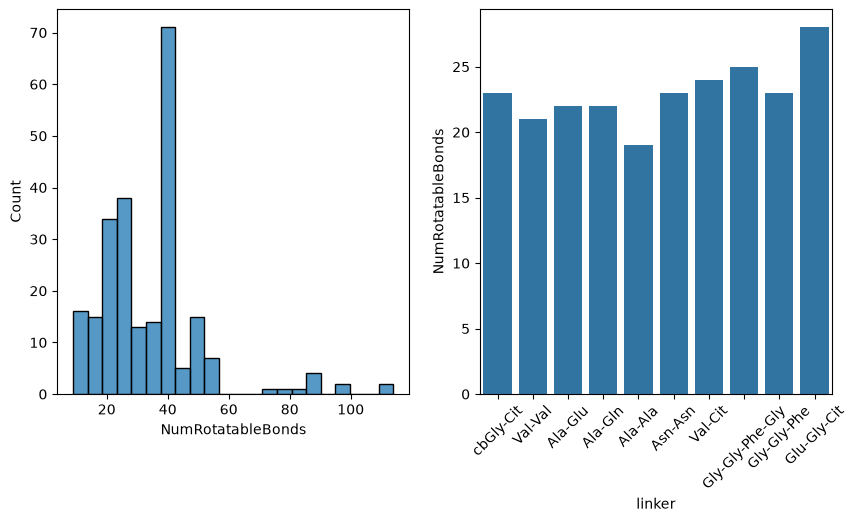

In [60]:
fig, ax = plt.subplots(1,2,figsize=(10,5))
descriptor="NumRotatableBonds"
min_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].min()
max_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].max()
print(f"{descriptor} range for JQ1-amine payload: {min_descriptor_inhouse} - {max_descriptor_inhouse}")
sns.barplot(data=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"], x="linker", y=descriptor, ax=ax[1]);
sns.histplot(data=wlp_df_pca_training, x=descriptor, ax=ax[0]);
plt.xticks(rotation=45)
plt.show(); 
plt.close()

NumHDonors range for JQ1-amine payload: 235.17999999999995 - 356.69999999999993


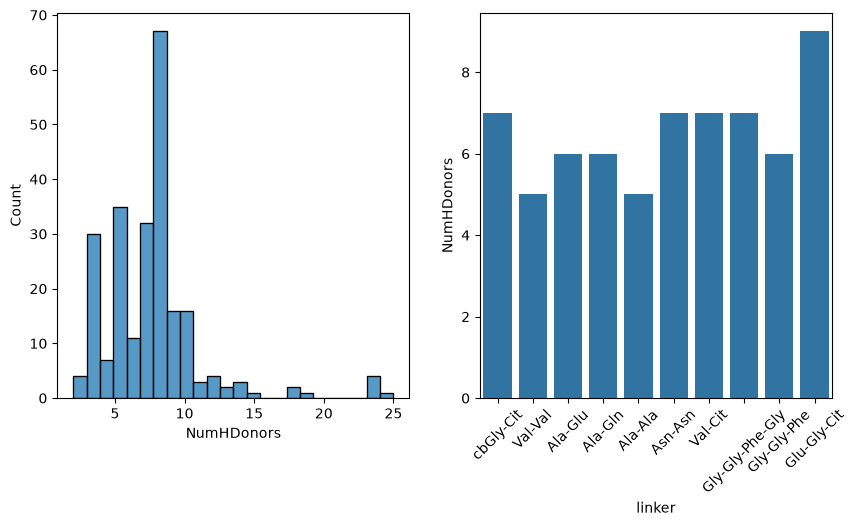

In [61]:
fig, ax = plt.subplots(1,2,figsize=(10,5))
descriptor="NumHDonors"
min_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].min()
max_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].max()
print(f"{descriptor} range for JQ1-amine payload: {min_descriptor_inhouse} - {max_descriptor_inhouse}")
sns.barplot(data=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"], x="linker", y=descriptor, ax=ax[1]);
sns.histplot(data=wlp_df_pca_training, x=descriptor, ax=ax[0]);
plt.xticks(rotation=45)
plt.show(); 
plt.close()

NumHAcceptors range for JQ1-amine payload: 235.17999999999995 - 356.69999999999993


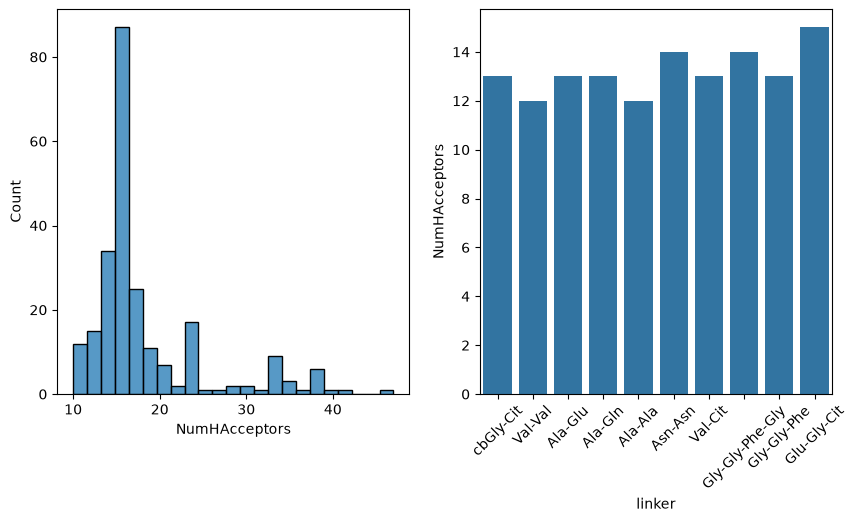

In [62]:
fig, ax = plt.subplots(1,2,figsize=(10,5))
descriptor="NumHAcceptors"
min_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].min()
max_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].max()
print(f"{descriptor} range for JQ1-amine payload: {min_descriptor_inhouse} - {max_descriptor_inhouse}")
sns.barplot(data=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"], x="linker", y=descriptor, ax=ax[1]);
sns.histplot(data=wlp_df_pca_training, x=descriptor, ax=ax[0]);
plt.xticks(rotation=45)
plt.show(); 
plt.close()

CrippenLogP range for JQ1-amine payload: 235.17999999999995 - 356.69999999999993


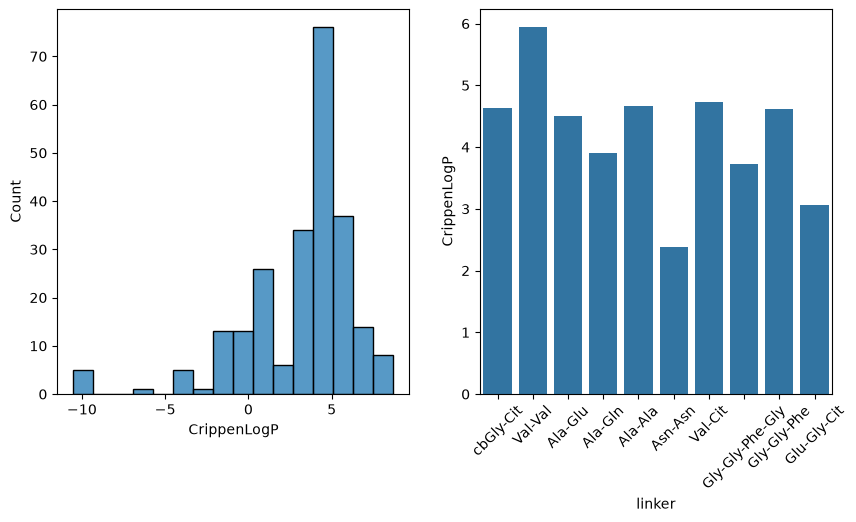

In [63]:
fig, ax = plt.subplots(1,2,figsize=(10,5))
descriptor="CrippenLogP"
min_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].min()
max_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].max()
print(f"{descriptor} range for JQ1-amine payload: {min_descriptor_inhouse} - {max_descriptor_inhouse}")
sns.barplot(data=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"], x="linker", y=descriptor, ax=ax[1]);
sns.histplot(data=wlp_df_pca_training, x=descriptor, ax=ax[0]);
plt.xticks(rotation=45)
plt.show(); 
plt.close()

TPSA range for JQ1-amine payload: 235.17999999999995 - 356.69999999999993


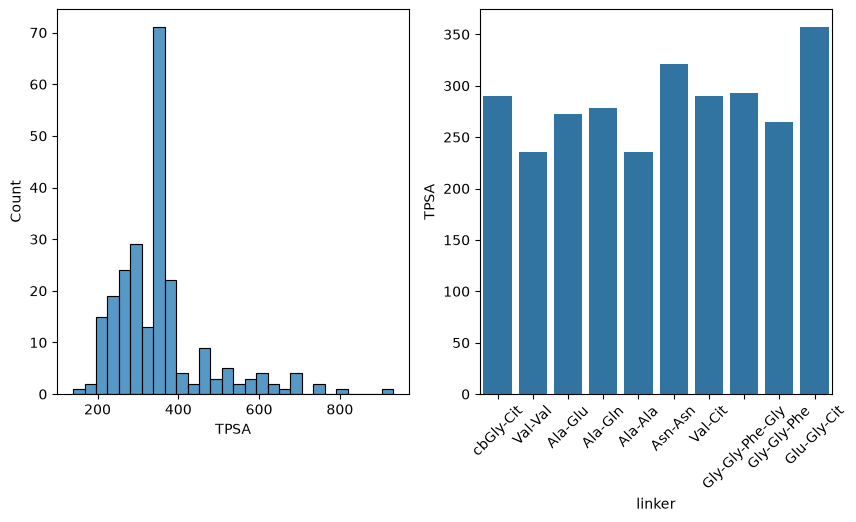

In [64]:
fig, ax = plt.subplots(1,2,figsize=(10,5))
descriptor="TPSA"
min_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].min()
max_descriptor_inhouse=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"]["TPSA"].max()
print(f"{descriptor} range for JQ1-amine payload: {min_descriptor_inhouse} - {max_descriptor_inhouse}")
sns.barplot(data=inhouse_pca_test[inhouse_pca_test["payload"]=="JQ1-amine"], x="linker", y=descriptor, ax=ax[1]);
sns.histplot(data=wlp_df_pca_training, x=descriptor, ax=ax[0]);
plt.xticks(rotation=45)
plt.show(); 
plt.close()